<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQC_IntrusionDetectionUNSW_deAbreu2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QML-IDS on UNSW-NB15: VQC, QSVM and QCNN for intrusion detection, step by step

This notebook re-implements, runs and checks the UNSW-NB15 experiments of

> D. de Abreu, C. E. Rothenberg and A. Abelém, "QML-IDS: Quantum Machine Learning Intrusion Detection System,"
> *IEEE Symposium on Computers and Communications (ISCC)*, 2024. https://doi.org/10.1109/ISCC61673.2024.10733655 (preprint: [arXiv:2410.16308](https://arxiv.org/abs/2410.16308))

**What the paper does.** It proposes a hybrid classical-quantum intrusion detection pipeline (monitoring, feature extraction, preprocessing, classical-to-quantum mapping, hybrid QML model, alert) and runs three quantum models, a **variational quantum classifier (VQC)**, a **quantum support vector machine (QSVM)** and a **quantum convolutional neural network (QCNN)**, built with Qiskit, against a random forest, an SVM and a CNN. It searches four feature maps, four ansätze and four optimizers, runs on six backends (a simulator and five IBM devices) and reports F1 for binary detection (Tables II-IV) and per attack family (Tables V-VII) on three datasets: UNSW-NB15, CIC-IDS-2017 and CICIoT2023.

**What this notebook does.** It covers the **UNSW-NB15 column only**: binary attack detection (Table IV and the UNSW-NB15 rows of Tables II-III) and the nine-category attack identification of Table V. The CIC-IDS-2017 column of the same experiment is reproduced in the sibling notebook `VQC_IntrusionDetection_deAbreu2025.ipynb` (the journal extension, which uses the same pipeline), and CICIoT2023 is not covered. The notebook

1. downloads the official UNSW-NB15 training and testing partitions from a public Hugging Face mirror and cleans them;
2. reduces each flow to 4 PCA angles (4 qubits) with every transform fitted on the training sample only;
3. shows the real data: class counts and labelled 2-D scatter plots of the real flows;
4. trains the VQC (default circuit, then a search over the paper's 4 x 4 x 4 grid), the QSVM (exact fidelity kernel) and the QCNN, and the classical RF, SVM and CNN on the same inputs;
5. draws every quantum circuit that is executed;
6. repeats the comparison over several seeds, replays the trained VQC on the stored noise models of the paper's five IBM devices, and classifies the nine attack categories;
7. prints a claim-by-claim comparison with the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. No GPU and no IBM account are needed. `FAST_MODE = True` runs the whole notebook in roughly 10 to 25 minutes depending on how busy the machine is (23 minutes on the shared 8-thread laptop used for validation); `FAST_MODE = False` uses larger samples and iteration budgets (about 85 minutes on that laptop). The saved outputs come from the `FAST_MODE = False` run; the wall-clock time of the run that produced them is printed in the last cell. The fast run's scores are much lower and noisier (120 training flows).

**Data access.** The UNSW-NB15 mirror used here is public. If you ever point `HF_REPO_MAIN` at a gated Hugging Face repository, add your own token in Colab under *Settings -> Secrets* as `HF_TOKEN` (locally: environment variable `HF_TOKEN`); the notebook reads it from there and never asks you to type it into a cell.

## The paper in one page

**Problem.** Detect network attacks (binary) and identify the attack family (multiclass) with quantum machine learning that fits NISQ devices.

**Method.** Hybrid QML (Section IV, Figs. 1-2): classical preprocessing -> feature map -> VQC / QSVM / QCNN -> classical post-processing -> alert. Four feature maps (`PauliFeatureMap`, `RawFeatureVector`, `ZFeatureMap`, `ZZFeatureMap`), four ansätze (`EfficientSU2`, `ExcitationPreserving`, `RealAmplitudes`, `TwoLocal`) and four optimizers (`COBYLA`, `ADAM`, `SPSA`, `GradientDescent`) from Table I; transpiler optimisation levels 0-3, resilience 0/1 and dynamical decoupling 0/1. The circuits in Fig. 1 use **4 qubits**.

**Data.** UNSW-NB15, CIC-IDS-2017, CICIoT2023 (no sample sizes, no split, no feature reduction reported).

**Claims we can test on UNSW-NB15.**

| Id | Claim | Where |
|---|---|---|
| C1 | Binary F1 on UNSW-NB15: VQC 88.10, QSVM 87.90, QCNN 87.32, RF 82.67, SVM 82.34, CNN 86.72 (%) | Table IV |
| C2 | The three QML models beat the three classical models on UNSW-NB15 (binary) | Table IV, Sec. VI-B |
| C3 | VQC is the best QML model on UNSW-NB15 (binary) | Table IV, Sec. VI-B |
| C4 | VQC F1 stays within about 3 points of the simulator on five IBM devices: 87.91 (Cairo), 88.10 (Kyoto), 85.78 (Brisbane), 87.75 (Osaka), 87.31 (Sherbrooke) vs 88.56 (QASM) | Tables II-III |
| C5 | Per-category F1 of nine attack families for six models (54 numbers) | Table V |
| C6 | Worms is the hardest category for every model (Table V: lowest F1 in every column); QML models lead on Exploits and Reconnaissance; the best classical model edges out the best quantum model on Shellcode | Table V, Sec. VI-C |

Paper numbers used below were transcribed from the PDF text of Tables II-V.

### What follows the paper and what had to be chosen

The paper fixes the pipeline, the model families, the circuit libraries and the metric. It reports no sample sizes, split, feature reduction, circuit repetitions, iteration budgets or shot counts, and publishes no code. Each choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UNSW-NB15 (version and partition not stated) | Official training partition (175,341 flows) and testing partition (82,332 flows) from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet` (fallback: `Mireu-Lab/UNSW-NB15`, whose file names are swapped); 10 labels = Normal + 9 attack categories |
| Training / test data | Not reported | Class-balanced random sample of the training partition (`N_TRAIN` flows); random sample of the testing partition at its natural class mix (`N_TEST` flows) |
| Cleaning | "normalization, handling missing values" | Infinities and missing values dropped (none present), duplicates kept (flag `DROP_DUPLICATES`); `stcpb`/`dtcpb` (random TCP sequence bases) dropped; `proto`, `service` and `state` one-hot encoded (8 most frequent values each); numeric features `log1p`-compressed (heavy tails) |
| Qubits / feature reduction | Not reported (Fig. 1 shows 4 qubits) | 4 qubits; standardise -> PCA to 4 components -> rescale to [0, pi], all fitted on the training sample |
| Quantum models | VQC, QSVM, QCNN (Qiskit) | The same three, simulated exactly (statevector / Aer) |
| Feature maps, ansätze, optimizers | 4 x 4 x 4 listed (Table I), winner not reported | Coordinate-wise search on a validation split (10 trainings) or the full 64-combination grid; the winner is retrained and tested once |
| Feature-map details | Fig. 1a: `H`, `P(2x)`, 2 repetitions | `z_feature_map(reps=2)`; `zz_feature_map(reps=2)`; `pauli_feature_map(reps=2, paulis=["Y","ZZ"])`; `raw_feature_vector` |
| QSVM kernel | "quantum kernel" | Exact fidelity kernel of a feature map chosen on the validation split; angle scale and `C` tuned on the validation split |
| QCNN | Fig. 1c, generic | Conv/pool blocks after Cong, Choi and Lukin, `<Z>` read-out, ZZ feature map on the 4 angles |
| Backends | QASM, IBM Cairo, Kyoto, Brisbane, Osaka, Sherbrooke (real hardware) | Aer simulator and Qiskit's *fake* versions of the same five devices (stored calibration snapshots); VQC only |
| Classical baselines | RF, SVM (scikit-learn), CNN (TensorFlow) | Same, each on the 4 PCA angles the quantum models see and on all standardised features |
| Multiclass task | 9 attack categories (Table V) | Attack flows only, 9 classes; VQC `outcome mod 9`, QSVM one-vs-one, QCNN one-vs-rest |
| Metric | F1 | F1 (attack = positive class); per-category F1 for Table V |
| Tolerance | - | A paper value is *reproduced* when the notebook is within 2 F1 points of it, *exceeded* / *not reached* otherwise |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and TensorFlow.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc pyarrow huggingface_hub
if importlib.util.find_spec("tensorflow") is None:       # CNN baseline; preinstalled on Colab
    %pip install -q tensorflow-cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False           # True: class demo (10-25 min); False: full budgets (about 85 min on an 8-thread laptop CPU)

SEED      = 42
SEEDS     = [42, 43] if FAST_MODE else [42, 43, 44]   # seeds for the repeated-run study (Section 8)
N_QUBITS  = 4               # CHOICE: the paper does not report qubit counts; its Fig. 1 circuits use 4

# Binary task (Normal vs attack)
N_TRAIN, N_TEST = (120, 300) if FAST_MODE else (300, 600)   # CHOICE: sample sizes are not reported
VQC_MAXITER      = 40  if FAST_MODE else 100     # CHOICE
QCNN_MAXITER     = 40  if FAST_MODE else 100     # CHOICE
SHOTS            = 1024                          # CHOICE

# Hyper-parameter study (paper Table I)
RUN_FULL_GRID    = False   # True: all 64 feature-map x ansatz x optimizer combinations (about 1.5-2 h)
GRID_TRAIN, GRID_VAL, GRID_MAXITER = (60, 60, 25) if FAST_MODE else (100, 100, 40)   # both come out of the training sample
GRAD_TRAIN, GRAD_MAXITER = (20, 5) if FAST_MODE else (30, 8)    # ADAM / GradientDescent use parameter-shift gradients and are slow

# QSVM: angle scale (kernel bandwidth) and SVM C are tuned on the validation split of the training sample
BANDWIDTHS = [0.5, 1.0, 2.0]
C_GRID     = [1.0, 10.0]

# Noisy-device study (paper Tables II-III)
NOISY_N_TEST = 60 if FAST_MODE else 100

# Multiclass task (paper Table V): attack flows only, 9 categories
RUN_MULTICLASS      = True
MC_TRAIN_PER_CLASS  = 25 if FAST_MODE else 30     # flows per attack category drawn from the training partition
MC_TEST_PER_CLASS   = 15 if FAST_MODE else 30     # flows per attack category drawn from the testing partition
MC_VQC_MAXITER      = 40 if FAST_MODE else 100
RUN_QCNN_MULTICLASS = not FAST_MODE               # one-vs-rest QCNN: 9 trainings
MC_QCNN_MAXITER     = 30

CNN_EPOCHS = 30 if FAST_MODE else 60

# Optional: run the trained VQC on real IBM hardware (needs a free IBM Quantum Platform API key)
IBM_TOKEN    = ""          # paste your key here, or leave empty to skip
IBM_INSTANCE = None

DROP_DUPLICATES = False   # CHOICE: UNSW-NB15 ships without IPs/ports/times, so identical rows are distinct flows; dropping them removes 39 % of the flows and 90 % of "Generic"
DATA_DIR = "unsw_nb15"     # downloaded files are cached here
LOCAL_TRAIN = ""           # optional: path to your own copy of the official training set (csv or parquet)
LOCAL_TEST  = ""           # optional: path to your own copy of the official testing set
NOTEBOOK_T0 = __import__("time").time()
print("FAST_MODE =", FAST_MODE, "| train/test flows", N_TRAIN, N_TEST, "| seeds", SEEDS)

FAST_MODE = False | train/test flows 300 600 | seeds [42, 43, 44]


In [3]:
import os, time, warnings, math, gc
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (z_feature_map, zz_feature_map, pauli_feature_map,
                                    real_amplitudes, efficient_su2, excitation_preserving, n_local, XGate)
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager, PassManager, Target
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling
from qiskit_aer.primitives import SamplerV2 as AerSampler

from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.circuit.library import raw_feature_vector
from qiskit_machine_learning.algorithms import VQC, QSVC, NeuralNetworkClassifier
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA, SPSA, ADAM, GradientDescent

import tensorflow as tf

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED); tf.random.set_seed(SEED); tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Hugging Face token: only needed if you point the loader at a gated repository (the default mirror is public).
# Never type a token into a cell; on Colab store it under Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | tensorflow 2.21.0 | numpy 2.5.4 | pandas 3.0.6


## 1. Network monitoring and data collection: UNSW-NB15

The paper's first step is capturing traffic. Here it is replaced by the public **UNSW-NB15** data set (Moustafa and Slay, MilCIS 2015, UNSW Canberra), generated in the Cyber Range Lab of the Australian Centre for Cyber Security. Each row is one network flow described by 42 features (durations, packet and byte counts per direction, TTLs, loads, jitter, TCP window and round-trip times, connection-count statistics, protocol, service and state), labelled `label` (0 = normal, 1 = attack) and `attack_cat` with one of nine attack categories: **Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms**.

The authors of the data set publish an official **training partition** (175,341 flows) and **testing partition** (82,332 flows). The paper does not say which flows it used; this notebook uses the official partitions, training on the first and testing on the second. The files come from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet` (the file names there match the official ones). If that mirror is unreachable, the code falls back to `Mireu-Lab/UNSW-NB15`, whose `train.csv` and `test.csv` carry the *swapped* contents (its `train.csv` has 82,332 rows = the official testing set), and swaps them back.

In [4]:
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback: train.csv holds the official TESTING set, test.csv the official TRAINING set

RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    # Common column names/labels across the two mirrors
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    # Return (official training partition, official testing partition) as DataFrames
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)    # official training set
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)   # official testing set
        return tidy(read_any(a)), tidy(read_any(b))

t0 = time.time()
raw_train, raw_test = load_unsw()
print(f"raw official partitions: training {raw_train.shape}, testing {raw_test.shape} ({time.time() - t0:.0f} s)")
assert len(raw_train) > len(raw_test), "partitions look swapped"

loaded from research-simulation26/unsw-nb15-parquet


raw official partitions: training (175341, 44), testing (82332, 44) (3 s)


## 2. Feature extraction and 3. data preprocessing

The flow statistics already come from the data set (Argus and Bro-IDS in the original capture). Preprocessing follows what the paper lists (normalisation, missing values) and adds what a quantum model needs:

1. Drop `stcpb` and `dtcpb`, the randomly chosen initial TCP sequence numbers: they are identifier-like noise with a range of billions (`# CHOICE`).
2. Coerce to numeric, replace infinities by missing values and drop those rows (none occur in this data set). Exact duplicate rows are **kept** by default (`DROP_DUPLICATES = False`, `# CHOICE`): the public CSVs have no IP addresses, ports or timestamps, so two identical rows are two different flows (for example thousands of identical DNS probes), and removing them would delete 39 % of the flows and about 90 % of the "Generic" category, changing the class mix of the official partitions. Set the flag to `True` to see the effect.
3. `proto`, `service` and `state` are categorical: one-hot encoded, keeping the 8 most frequent values of each and pooling the rest (`# CHOICE`). The numeric features are heavy-tailed (rates and loads span ten orders of magnitude), so they are compressed with `log1p` before standardising (`# CHOICE`).
4. Draw a **class-balanced** training sample and a test sample at the testing partition's **natural class mix**. A statevector simulation costs time per flow, so the quantum models see hundreds of flows, not hundreds of thousands.
5. Fit the encoder, scaler and PCA on the training sample only, then apply them to the test sample (no information from test flows reaches training).
6. Reduce to `N_QUBITS` principal components (one feature per qubit) and rescale each to [0, pi], the range of a rotation angle. Test angles are clipped to [0, pi].

In [5]:
DROP_COLS = ["stcpb", "dtcpb"]                     # CHOICE: random TCP sequence bases
CAT_COLS  = ["proto", "service", "state"]
ATTACKS   = ["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]   # the 9 categories of Table V
CATS      = ["Normal"] + ATTACKS

def clean(df, name):
    n0 = len(df)
    df = df.drop(columns=DROP_COLS)
    num = [c for c in df.columns if c not in CAT_COLS + ["attack_cat"]]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]] = df[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]].fillna(0)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    n1 = len(df)
    if DROP_DUPLICATES:
        df = df.drop_duplicates()
    df = df.reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    print(f"{name}: {n0:,} flows -> {n1:,} without missing/infinite values -> {len(df):,} kept (DROP_DUPLICATES = {DROP_DUPLICATES})")
    return df

train_part = clean(raw_train, "training partition")
test_part  = clean(raw_test, "testing partition")
NUM_COLS = [c for c in train_part.columns if c not in CAT_COLS + ["attack_cat", "label"]]
FEATS = NUM_COLS + CAT_COLS
print(len(NUM_COLS), "numeric +", len(CAT_COLS), "categorical features")
print("training partition after cleaning:", train_part["attack_cat"].value_counts().to_dict())
print("testing partition after cleaning :", test_part["attack_cat"].value_counts().to_dict())

training partition: 175,341 flows -> 175,341 without missing/infinite values -> 175,341 kept (DROP_DUPLICATES = False)


testing partition: 82,332 flows -> 82,332 without missing/infinite values -> 82,332 kept (DROP_DUPLICATES = False)
37 numeric + 3 categorical features
training partition after cleaning: {'Normal': 56000, 'Generic': 40000, 'Exploits': 33393, 'Fuzzers': 18184, 'DoS': 12264, 'Reconnaissance': 10491, 'Analysis': 2000, 'Backdoor': 1746, 'Shellcode': 1133, 'Worms': 130}
testing partition after cleaning : {'Normal': 37000, 'Generic': 18871, 'Exploits': 11132, 'Fuzzers': 6062, 'DoS': 4089, 'Reconnaissance': 3496, 'Analysis': 677, 'Backdoor': 583, 'Shellcode': 378, 'Worms': 44}


In [6]:
def log1p_clip(X):
    return np.log1p(np.clip(X, 0, None))

def make_encoder():
    # numeric: log1p; categorical: one-hot of the 8 most frequent values (rest pooled)
    return ColumnTransformer([
        ("num", FunctionTransformer(log1p_clip), NUM_COLS),
        ("cat", OneHotEncoder(max_categories=8, handle_unknown="infrequent_if_exist", sparse_output=False), CAT_COLS)])

def make_to_qubits(seed):
    # encoder -> standardise -> PCA (one component per qubit) -> angles in [0, pi]; fitted on training data only
    return Pipeline([("enc", make_encoder()), ("std", StandardScaler()),
                     ("pca", PCA(n_components=N_QUBITS, random_state=seed)),
                     ("mm", MinMaxScaler(feature_range=(0, np.pi)))])

def draw_binary(seed, n_train=None, n_test=None):
    # Class-balanced training sample (official training partition) + natural-mix test sample (official testing partition)
    n_train, n_test = n_train or N_TRAIN, n_test or N_TEST
    tr = train_part.groupby("label", group_keys=False).sample(n=n_train // 2, random_state=seed)
    tr = tr.sample(frac=1, random_state=seed).reset_index(drop=True)
    te = test_part.sample(n=n_test, random_state=seed).reset_index(drop=True)
    tq = make_to_qubits(seed).fit(tr[FEATS])
    out = dict(tr=tr, te=te, y_train=tr["label"].to_numpy(), y_test=te["label"].to_numpy(), tq=tq)
    out["Z_train"] = tq[:-1].transform(tr[FEATS])                               # raw PCA coordinates
    out["X_train"] = tq.transform(tr[FEATS])                                    # angles in [0, pi]
    out["X_test"]  = np.clip(tq.transform(te[FEATS]), 0, np.pi)
    out["S_train"] = tq[:2].transform(tr[FEATS]); out["S_test"] = tq[:2].transform(te[FEATS])   # all standardised features (classical baselines)
    return out

def draw_multiclass(seed):
    # Attack flows only: balanced per-category samples from the training partition (fit) and the testing partition (evaluate)
    tr = pd.concat([train_part[train_part.attack_cat == a].sample(n=min(MC_TRAIN_PER_CLASS, (train_part.attack_cat == a).sum()), random_state=seed) for a in ATTACKS])
    te = pd.concat([test_part[test_part.attack_cat == a].sample(n=min(MC_TEST_PER_CLASS, (test_part.attack_cat == a).sum()), random_state=seed) for a in ATTACKS])
    tr = tr.sample(frac=1, random_state=seed).reset_index(drop=True); te = te.sample(frac=1, random_state=seed).reset_index(drop=True)
    idx = {a: i for i, a in enumerate(ATTACKS)}
    tq = make_to_qubits(seed).fit(tr[FEATS])
    out = dict(tr=tr, te=te, y_train=tr["attack_cat"].map(idx).to_numpy(), y_test=te["attack_cat"].map(idx).to_numpy(), tq=tq)
    out["Z_train"] = tq[:-1].transform(tr[FEATS]); out["X_train"] = tq.transform(tr[FEATS])
    out["X_test"] = np.clip(tq.transform(te[FEATS]), 0, np.pi)
    out["S_train"] = tq[:2].transform(tr[FEATS]); out["S_test"] = tq[:2].transform(te[FEATS])
    return out

B = draw_binary(SEED)
tr_df, te_df = B["tr"], B["te"]
X_train, X_test, y_train, y_test = B["X_train"], B["X_test"], B["y_train"], B["y_test"]
pca = B["tq"].named_steps["pca"]
print("binary task: train", X_train.shape, "(balanced:", np.bincount(y_train).tolist(), ") | test", X_test.shape, "(natural mix:", np.bincount(y_test).tolist(), ")")
print("all standardised features after encoding:", B["S_train"].shape[1], "| variance kept by", N_QUBITS, "components:", f"{pca.explained_variance_ratio_.sum():.1%}")
if RUN_MULTICLASS:
    M = draw_multiclass(SEED)
    print("multiclass task: train", M["X_train"].shape, "test", M["X_test"].shape, "| test flows per category:", dict(zip(ATTACKS, np.bincount(M["y_test"], minlength=9).tolist())))

binary task: train (300, 4) (balanced: [150, 150] ) | test (600, 4) (natural mix: [273, 327] )
all standardised features after encoding: 56 | variance kept by 4 components: 58.4%


multiclass task: train (270, 4) test (270, 4) | test flows per category: {'Analysis': 30, 'Backdoor': 30, 'DoS': 30, 'Exploits': 30, 'Fuzzers': 30, 'Generic': 30, 'Reconnaissance': 30, 'Shellcode': 30, 'Worms': 30}


## Dataset Exploration and Visualisation

Everything below shows the **real UNSW-NB15 flows** and their ground-truth labels. First the shape, the feature names and the original label values; then the class distributions of both official partitions and of the samples used here; then 2-D scatter plots of the real training flows, coloured by their true class: the first two PCA coordinates (PCA fitted on the training sample), and the same points after the MinMax scaling to angles in [0, pi] that the 4-qubit models receive. The binary training sample is coloured by attack category (multiclass labels kept) and by the binary label; the nine-category sample of the multiclass task is plotted the same way.

In [7]:
print("official training partition (raw)  :", raw_train.shape, "| after cleaning:", train_part.shape)
print("official testing partition (raw)   :", raw_test.shape, "| after cleaning:", test_part.shape)
print(f"\nfeatures used ({len(FEATS)}): numeric ({len(NUM_COLS)}) = {NUM_COLS}\n  categorical ({len(CAT_COLS)}) = {CAT_COLS}")
print("\noriginal labels")
print("  label (0 normal / 1 attack), raw training :", raw_train["label"].value_counts().to_dict(), "| raw testing:", raw_test["label"].value_counts().to_dict())
print("  attack_cat, raw training :", raw_train["attack_cat"].value_counts().to_dict())
print("  attack_cat, raw testing  :", raw_test["attack_cat"].value_counts().to_dict())
print("\nsample used for the binary task (seed %d)" % SEED)
print("  train attack_cat:", tr_df["attack_cat"].value_counts().to_dict())
print("  test  attack_cat:", te_df["attack_cat"].value_counts().to_dict())
display(train_part[FEATS + ["attack_cat", "label"]].head(5))
display(train_part[NUM_COLS].describe().T[["mean", "std", "min", "max"]].head(12))

official training partition (raw)  : (175341, 44) | after cleaning: (175341, 42)
official testing partition (raw)   : (82332, 44) | after cleaning: (82332, 42)

features used (40): numeric (37) = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
  categorical (3) = ['proto', 'service', 'state']

original labels
  label (0 normal / 1 attack), raw training : {1: 119341, 0: 56000} | raw testing: {1: 45332, 0: 37000}
  attack_cat, raw training : {'Normal': 56000, 'Generic': 40000, 'Exploits': 33393, 'Fuzzers': 18184, 'DoS': 12264, 'Reconnaissance': 10491, 'Analysis': 2000, 'Backdoor': 1746, 'Shellcode': 11

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sintpkt,dintpkt,sjit,djit,swin,dwin,tcprtt,synack,ackdat,smeansz,dmeansz,trans_depth,res_bdy_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,proto,service,state,attack_cat,label
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,tcp,-,FIN,Normal,0
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,tcp,-,FIN,Normal,0
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,tcp,-,FIN,Normal,0
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,tcp,ftp,FIN,Normal,0
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,tcp,-,FIN,Normal,0


,mean,std,min,max
dur,1.359389e+00,6.480249e+00,0.0,5.999999e+01
spkts,2.029866e+01,1.368876e+02,1.0,9.616000e+03
dpkts,1.896959e+01,1.102583e+02,0.0,1.097400e+04
sbytes,8.844844e+03,1.747656e+05,28.0,1.296523e+07
dbytes,1.492892e+04,1.436542e+05,0.0,1.465555e+07
rate,9.540619e+04,1.654010e+05,0.0,1.000000e+06
sttl,1.795470e+02,1.029400e+02,0.0,2.550000e+02
dttl,7.960957e+01,1.105069e+02,0.0,2.540000e+02
sload,7.345403e+07,1.883574e+08,0.0,5.988000e+09
dload,6.712056e+05,2.421312e+06,0.0,2.242273e+07


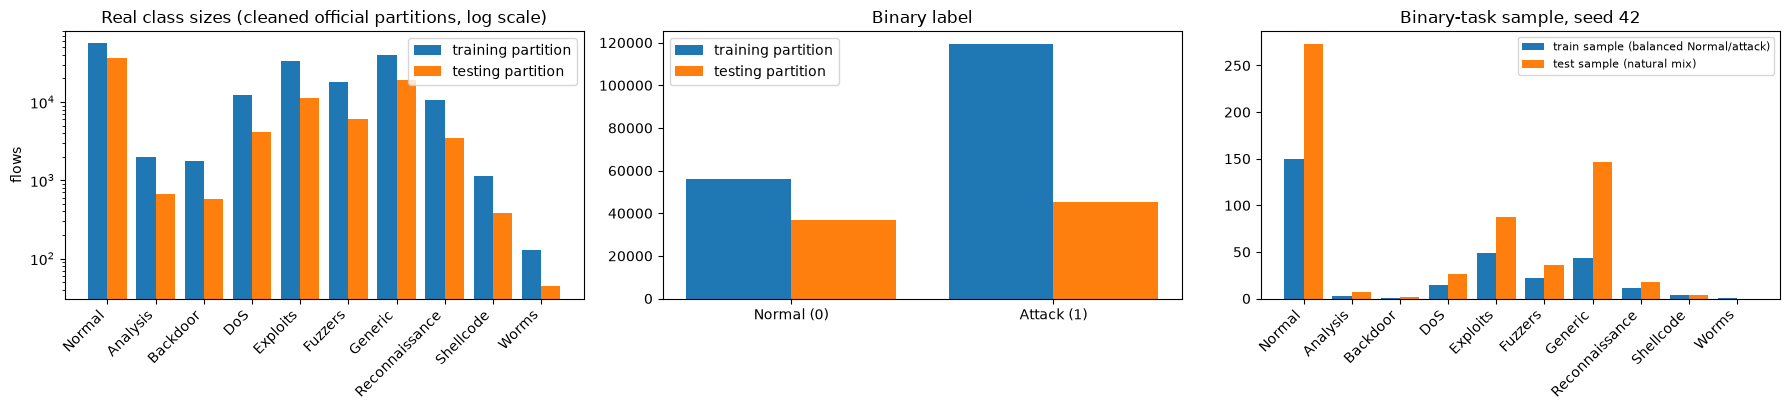

In [8]:
PAL = dict(zip(CATS, plt.cm.tab10(np.arange(10))))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
w = 0.4
cnt_tr = train_part["attack_cat"].value_counts().reindex(CATS); cnt_te = test_part["attack_cat"].value_counts().reindex(CATS)
ax[0].bar(np.arange(10) - w / 2, cnt_tr.values, w, label="training partition", color="tab:blue")
ax[0].bar(np.arange(10) + w / 2, cnt_te.values, w, label="testing partition", color="tab:orange")
ax[0].set_yscale("log"); ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CATS, rotation=45, ha="right"); ax[0].legend()
ax[0].set_title("Real class sizes (cleaned official partitions, log scale)"); ax[0].set_ylabel("flows")
bin_tr = train_part["label"].value_counts().sort_index(); bin_te = test_part["label"].value_counts().sort_index()
ax[1].bar(np.arange(2) - w / 2, bin_tr.values, w, label="training partition", color="tab:blue")
ax[1].bar(np.arange(2) + w / 2, bin_te.values, w, label="testing partition", color="tab:orange")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Normal (0)", "Attack (1)"]); ax[1].legend(); ax[1].set_title("Binary label")
s_tr = tr_df["attack_cat"].value_counts().reindex(CATS).fillna(0); s_te = te_df["attack_cat"].value_counts().reindex(CATS).fillna(0)
ax[2].bar(np.arange(10) - w / 2, s_tr.values, w, label="train sample (balanced Normal/attack)", color="tab:blue")
ax[2].bar(np.arange(10) + w / 2, s_te.values, w, label="test sample (natural mix)", color="tab:orange")
ax[2].set_xticks(range(10)); ax[2].set_xticklabels(CATS, rotation=45, ha="right"); ax[2].legend(fontsize=8); ax[2].set_title("Binary-task sample, seed %d" % SEED)
plt.tight_layout(); plt.show()

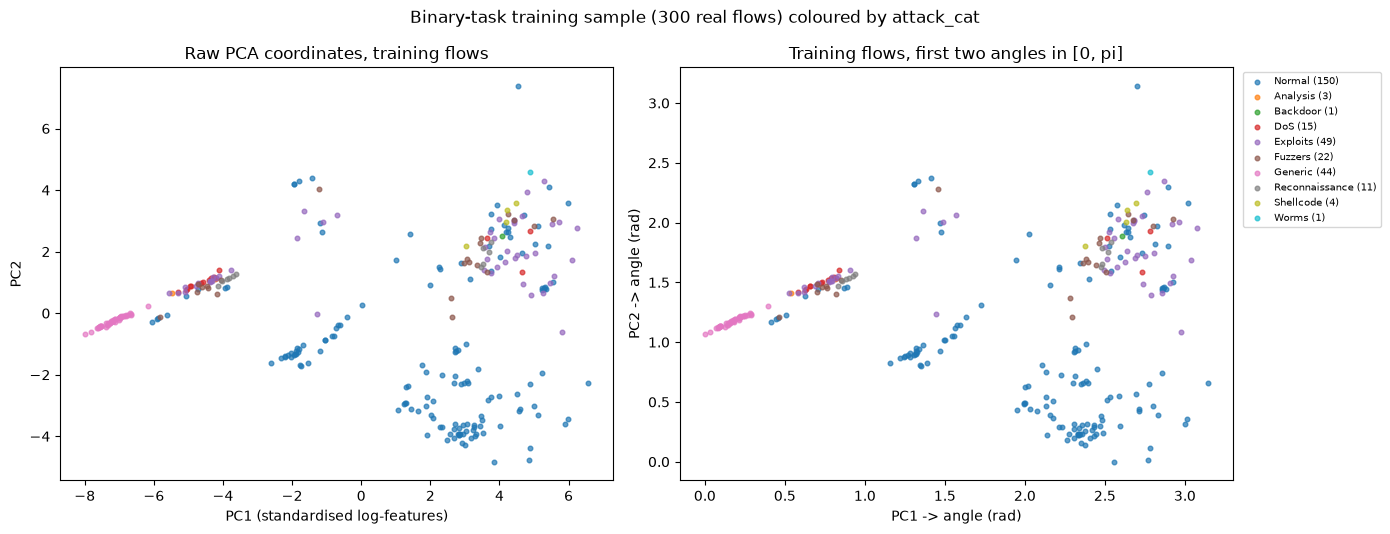

In [9]:
def scatter_pair(Z, A, labels, names, palette, title):
    # left: raw PCA coordinates, right: the same flows as angles in [0, pi]; every point is one real flow
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
    for k, name in enumerate(names):
        m = labels == k
        if m.sum() == 0: continue
        ax[0].scatter(Z[m, 0], Z[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
        ax[1].scatter(A[m, 0], A[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
    ax[0].set_xlabel("PC1 (standardised log-features)"); ax[0].set_ylabel("PC2"); ax[0].set_title("Raw PCA coordinates, training flows")
    ax[1].set_xlabel("PC1 -> angle (rad)"); ax[1].set_ylabel("PC2 -> angle (rad)"); ax[1].set_title("Training flows, first two angles in [0, pi]")
    ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.suptitle(title); plt.tight_layout(); plt.show()

# binary-task sample coloured by the original attack category (multiclass labels kept)
cat_idx = tr_df["attack_cat"].map({c: i for i, c in enumerate(CATS)}).to_numpy()
scatter_pair(B["Z_train"], B["X_train"], cat_idx, CATS, PAL, "Binary-task training sample (%d real flows) coloured by attack_cat" % len(tr_df))

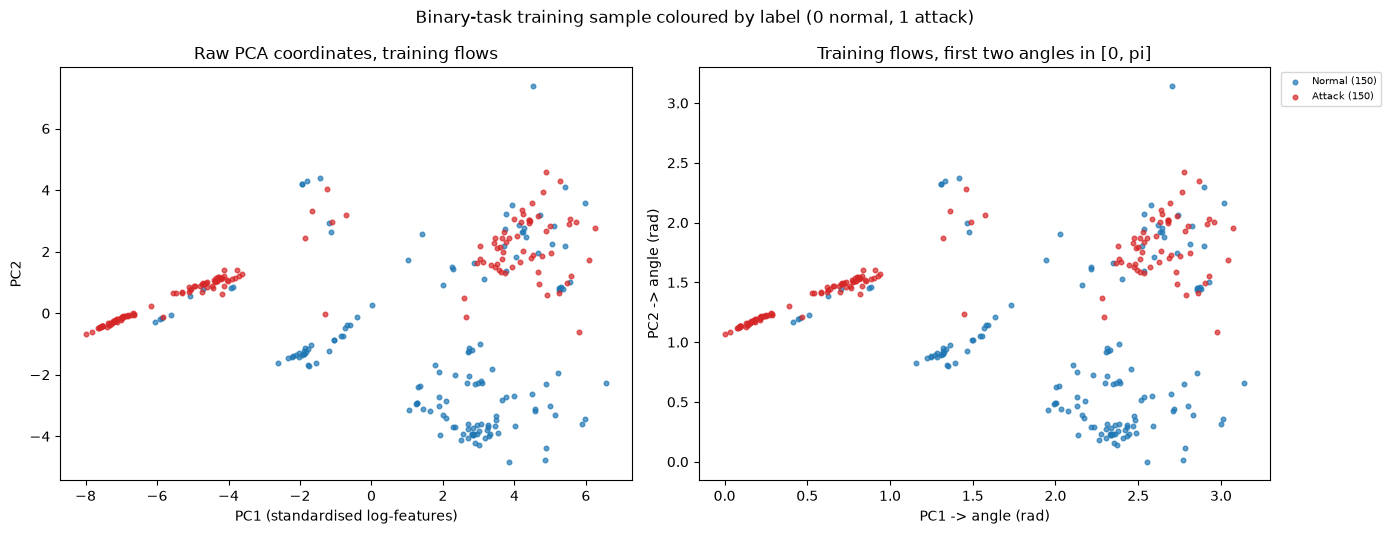

variance explained by the 4 components: [0.358 0.093 0.073 0.061] -> total 58.4%


In [10]:
# same flows coloured by the binary ground-truth label
BPAL = {"Normal": "tab:blue", "Attack": "tab:red"}
scatter_pair(B["Z_train"], B["X_train"], B["y_train"], ["Normal", "Attack"], BPAL, "Binary-task training sample coloured by label (0 normal, 1 attack)")
print("variance explained by the 4 components:", np.round(pca.explained_variance_ratio_, 3), "-> total", f"{pca.explained_variance_ratio_.sum():.1%}")

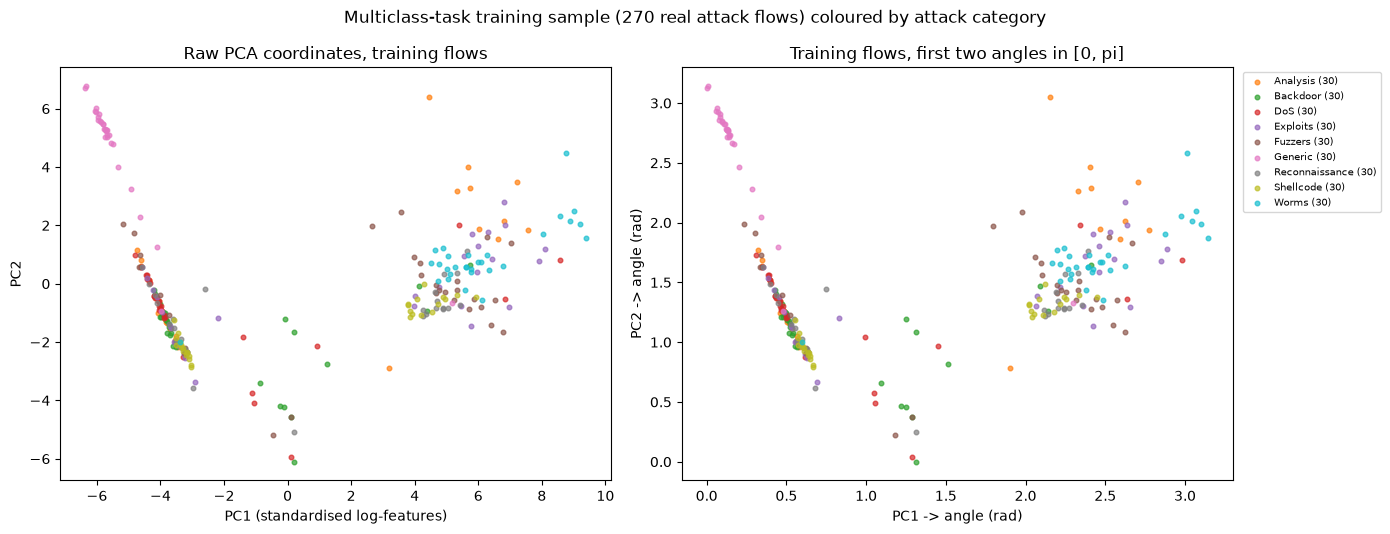

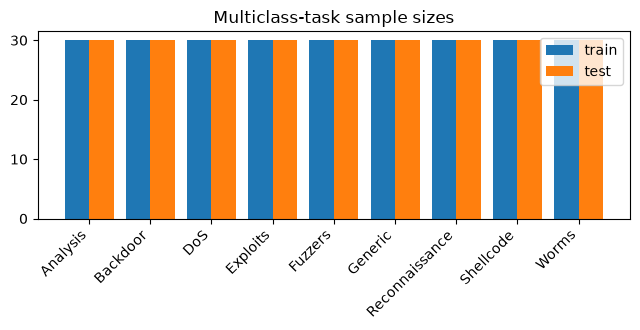

In [11]:
# multiclass-task sample: the nine attack categories (PCA fitted on this sample's training split)
if RUN_MULTICLASS:
    scatter_pair(M["Z_train"], M["X_train"], M["y_train"], ATTACKS, PAL, "Multiclass-task training sample (%d real attack flows) coloured by attack category" % len(M["tr"]))
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.bar(range(9), np.bincount(M["y_train"], minlength=9) , width=.4, align="edge", label="train", color="tab:blue")
    ax.bar(np.arange(9) + .4, np.bincount(M["y_test"], minlength=9), width=.4, align="edge", label="test", color="tab:orange")
    ax.set_xticks(np.arange(9) + .4); ax.set_xticklabels(ATTACKS, rotation=45, ha="right"); ax.legend(); ax.set_title("Multiclass-task sample sizes")
    plt.tight_layout(); plt.show()

## 4. Classical-to-quantum mapping: the four feature maps

A feature map $U_\phi(x)$ writes a classical vector $x$ into a quantum state $|\phi(x)\rangle = U_\phi(x)|0\rangle^{\otimes q}$. The paper tests the four maps of Qiskit's circuit library (Table I):

- **ZFeatureMap**: Hadamards followed by single-qubit phase rotations $P(2x_i)$, repeated twice (the circuit in the paper's Fig. 1a). No entanglement.
- **ZZFeatureMap**: adds two-qubit $ZZ$ phase terms $(\pi - x_i)(\pi - x_j)$, which entangle the features (Havlicek et al., Nature, 2019).
- **PauliFeatureMap**: the general form, where the Pauli strings are chosen. The paper does not say which; this notebook uses `["Y", "ZZ"]` so that it differs from ZZFeatureMap (`["Z", "ZZ"]`).
- **RawFeatureVector**: amplitude encoding. The normalised feature vector becomes the state's amplitudes, so 4 features need only $\log_2 4 = 2$ qubits.

The drawings of all four maps, of the four ansätze and of the circuits that are actually trained follow in the circuit-drawing section below, once the models exist.

In [12]:
FEATURE_MAPS = ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap", "RawFeatureVector"]
ANSATZE      = ["RealAmplitudes", "EfficientSU2", "ExcitationPreserving", "TwoLocal"]
OPTIMIZERS   = ["COBYLA", "SPSA", "ADAM", "GradientDescent"]

def build_feature_map(name, n=N_QUBITS):
    if name == "ZFeatureMap":      return z_feature_map(n, reps=2)                         # CHOICE: reps=2 (as in the paper's Fig. 1a)
    if name == "ZZFeatureMap":     return zz_feature_map(n, reps=2, entanglement="linear")
    if name == "PauliFeatureMap":  return pauli_feature_map(n, reps=2, paulis=["Y", "ZZ"])  # CHOICE: Pauli strings
    if name == "RawFeatureVector": return raw_feature_vector(n)                            # n features -> log2(n) qubits
    raise ValueError(name)

def build_ansatz(name, n):
    if name == "RealAmplitudes":       return real_amplitudes(n, reps=2)                    # Fig. 1b shows 12 RY angles on 4 qubits = 3 layers = reps 2
    if name == "EfficientSU2":         return efficient_su2(n, reps=2)
    if name == "ExcitationPreserving":   # its "Interaction" gate is rewritten into gates the Aer simulator knows
        return transpile(excitation_preserving(n, reps=2), basis_gates=["rz", "rx", "ry", "cx", "h", "p"], optimization_level=0)
    if name == "TwoLocal":             return n_local(n, ["ry", "rz"], "cz", reps=2)       # CHOICE: reps
    raise ValueError(name)

def build_optimizer(name, maxiter):
    if name == "COBYLA":          return COBYLA(maxiter=maxiter)
    if name == "SPSA":            return SPSA(maxiter=maxiter)
    if name == "ADAM":            return ADAM(maxiter=maxiter, lr=0.05)                     # CHOICE: learning rates
    if name == "GradientDescent": return GradientDescent(maxiter=maxiter, learning_rate=0.1)
    raise ValueError(name)

for name in FEATURE_MAPS:
    fm = build_feature_map(name)
    print(f"{name:17s}: {fm.num_qubits} qubits, {fm.num_parameters} input parameters")
for name in ANSATZE:
    an = build_ansatz(name, N_QUBITS)
    print(f"{name:21s}: {an.num_qubits} qubits, {an.num_parameters} trainable parameters")

ZFeatureMap      : 4 qubits, 4 input parameters
ZZFeatureMap     : 4 qubits, 4 input parameters
PauliFeatureMap  : 4 qubits, 4 input parameters
RawFeatureVector : 2 qubits, 4 input parameters
RealAmplitudes       : 4 qubits, 12 trainable parameters
EfficientSU2         : 4 qubits, 24 trainable parameters


ExcitationPreserving : 4 qubits, 24 trainable parameters
TwoLocal             : 4 qubits, 24 trainable parameters


## 5. Hybrid QML processing: the variational quantum classifier

The VQC appends a trainable circuit $U(\theta)$, the ansatz, to the feature map and measures every qubit:

$$|\psi(x,\theta)\rangle = U(\theta)\,U_\phi(x)\,|0\rangle^{\otimes q}.$$

Qiskit's `VQC` reads the class from the measured bitstring: for two classes the parity of the bitstring (outcome `k` -> class `k mod 2`), for $K$ classes `k mod K`. A classical optimiser adjusts $\theta$ to minimise the cross-entropy between these probabilities and the true labels. The quantum computer prepares and measures states; all learning happens on the classical side.

The first model uses a common default configuration (ZZFeatureMap + RealAmplitudes + COBYLA). Section 5b searches the paper's hyper-parameter space.

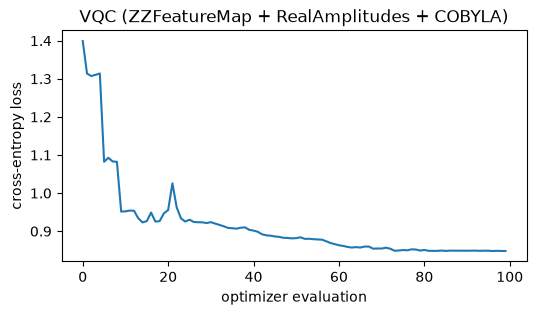

trained+predicted in 504 s | test F1 (attack = positive) = 0.5761


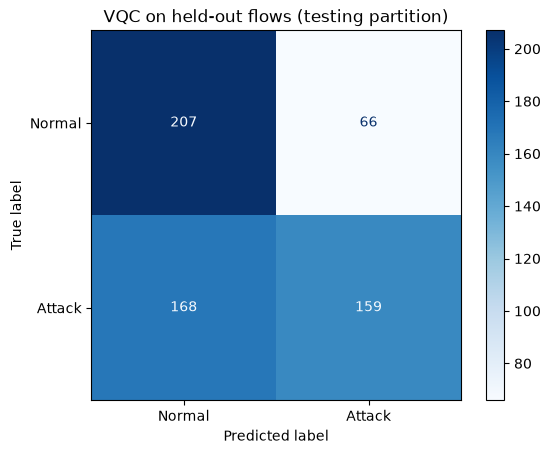

In [13]:
def make_live_plot(title, every=5):
    # Return (callback, history). The callback redraws the loss curve every few evaluations.
    history = []
    def callback(*args):
        # COBYLA / ADAM / GradientDescent call callback(weights, loss); SPSA calls (n_evals, weights, loss, step, accepted)
        history.append(args[1] if len(args) == 2 else args[2])
        if len(history) % every == 0:
            clear_output(wait=True)
            plt.figure(figsize=(6, 3)); plt.plot(history); plt.xlabel("optimizer evaluation")
            plt.ylabel("cross-entropy loss"); plt.title(title); plt.show()
    return callback, history

def make_vqc(fm_name, an_name, opt_name, maxiter, callback=None):
    fm = build_feature_map(fm_name)
    an = build_ansatz(an_name, fm.num_qubits)
    # Aer cannot simulate RawFeatureVector's ParameterizedInitialize instruction, so that map uses Qiskit's reference sampler
    sampler = (StatevectorSampler(default_shots=SHOTS, seed=SEED) if fm_name == "RawFeatureVector"
               else AerSampler(default_shots=SHOTS, seed=SEED))
    return VQC(feature_map=fm, ansatz=an, optimizer=build_optimizer(opt_name, maxiter), callback=callback, sampler=sampler)

algorithm_globals.random_seed = SEED
cb, hist = make_live_plot("VQC (ZZFeatureMap + RealAmplitudes + COBYLA)")
vqc = make_vqc("ZZFeatureMap", "RealAmplitudes", "COBYLA", VQC_MAXITER, callback=cb)
t0 = time.time(); vqc.fit(X_train, y_train); y_pred_vqc = vqc.predict(X_test); t_vqc = time.time() - t0

print(f"trained+predicted in {t_vqc:.0f} s | test F1 (attack = positive) = {f1_score(y_test, y_pred_vqc):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_vqc), display_labels=["Normal", "Attack"]).plot(cmap="Blues")
plt.title("VQC on held-out flows (testing partition)"); plt.show()

### 6-7. Output interpretation and alert generation

The paper's last two steps turn the measured class into an alert. The cell shows this for a few test flows: the measured odd-parity probability is the model's attack score, and a score above 0.5 raises an alert.

In [14]:
proba = vqc.predict_proba(X_test[:8])
for i, p in enumerate(proba):
    verdict = "ALERT: attack" if p[1] >= 0.5 else "ok"
    truth = te_df.loc[i, "attack_cat"]
    print(f"flow {i}: p(attack) = {p[1]:.2f} -> {verdict:13s} (true category: {truth})")

flow 0: p(attack) = 0.57 -> ALERT: attack (true category: Normal)
flow 1: p(attack) = 0.13 -> ok            (true category: Generic)
flow 2: p(attack) = 0.73 -> ALERT: attack (true category: Generic)
flow 3: p(attack) = 0.57 -> ALERT: attack (true category: Normal)
flow 4: p(attack) = 0.10 -> ok            (true category: Exploits)
flow 5: p(attack) = 0.74 -> ALERT: attack (true category: Generic)
flow 6: p(attack) = 0.07 -> ok            (true category: Normal)
flow 7: p(attack) = 0.15 -> ok            (true category: Exploits)


## 5b. Hyper-parameter study (paper Table I)

The paper lists the options it searched - four feature maps, four ansätze and four classical optimizers - but reports neither the per-combination scores nor the combination behind its headline numbers. This section runs that search so that the "VQC (tuned)" row of the comparison is a reproducible choice rather than a guess.

Two rules keep the search honest:

- **Selection uses a validation split of the training sample only.** `GRID_TRAIN` flows are used to fit, `GRID_VAL` other training flows to score. The test flows are untouched until the winning configuration has been retrained on the full training sample.
- **The budget is stated.** With `RUN_FULL_GRID = False` (default) the search is coordinate-wise: all four feature maps with RealAmplitudes + COBYLA, then all four ansätze with the best map, then all four optimizers with the best map and ansatz, 10 trainings instead of 64. `RUN_FULL_GRID = True` evaluates all 64 combinations (about 1.5-2 h on a Colab CPU). ADAM and GradientDescent need parameter-shift gradients (two extra circuits per trainable angle per flow per step), so they get the smaller `GRAD_TRAIN` / `GRAD_MAXITER` budget; the table records the budget next to each score.

Every combination starts from the same random initial angles (`algorithm_globals.random_seed` is reset before each training). One corner of the grid cannot be run as described: ADAM and GradientDescent need a gradient, and Qiskit's parameter-shift rule does not exist for RawFeatureVector's amplitude-encoding instruction. Those combinations are listed with an empty score. (With RawFeatureVector, `VQC` encodes 4 features on 2 qubits, so its ansatz is the 2-qubit version.)

grid: fit on 100 training flows, score on 100 validation flows


ZFeatureMap      RealAmplitudes       COBYLA          val F1 =  83.33 %  (  50.9 s)


ZZFeatureMap     RealAmplitudes       COBYLA          val F1 =  60.87 %  (  61.5 s)


PauliFeatureMap  RealAmplitudes       COBYLA          val F1 =  69.23 %  (  58.3 s)


RawFeatureVector RealAmplitudes       COBYLA          val F1 =  70.97 %  (  65.5 s)


...

ZFeatureMap      RealAmplitudes       SPSA            val F1 =  81.90 %  ( 151.4 s)


ZFeatureMap      RealAmplitudes       ADAM            val F1 =  65.73 %  ( 109.4 s)


ZFeatureMap      RealAmplitudes       GradientDescent val F1 =  52.38 %  (  97.6 s)



10 combinations (10 trained) in 13.0 min
BEST = Combo(feature_map='ZFeatureMap', ansatz='RealAmplitudes', optimizer='COBYLA')


,feature_map,ansatz,optimizer,train flows,maxiter,val F1 (%),time (s),note
0,ZFeatureMap,RealAmplitudes,COBYLA,100,40,83.33,50.9,
1,ZFeatureMap,EfficientSU2,COBYLA,100,40,81.90,55.4,
2,ZFeatureMap,RealAmplitudes,SPSA,100,40,81.90,151.4,
3,ZFeatureMap,TwoLocal,COBYLA,100,40,81.36,54.3,
4,RawFeatureVector,RealAmplitudes,COBYLA,100,40,70.97,65.5,
5,PauliFeatureMap,RealAmplitudes,COBYLA,100,40,69.23,58.3,
6,ZFeatureMap,ExcitationPreserving,COBYLA,100,40,69.03,61.2,
7,ZFeatureMap,RealAmplitudes,ADAM,30,8,65.73,109.4,reduced gradient budget
8,ZZFeatureMap,RealAmplitudes,COBYLA,100,40,60.87,61.5,
9,ZFeatureMap,RealAmplitudes,GradientDescent,30,8,52.38,97.6,reduced gradient budget


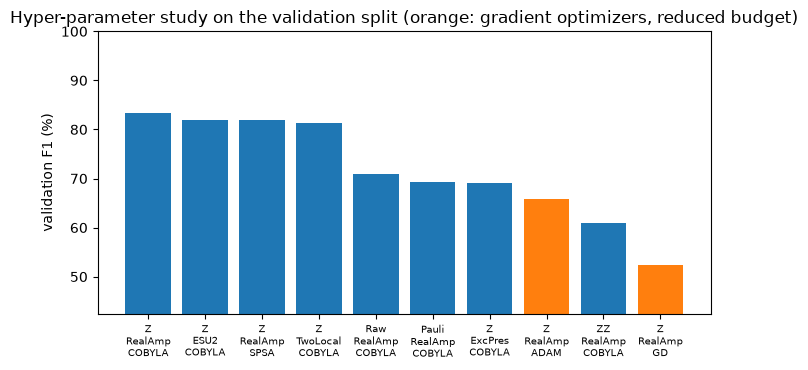

In [15]:
from collections import namedtuple
from itertools import product

Combo = namedtuple("Combo", ["feature_map", "ansatz", "optimizer"])
GRAD_OPTS = ("ADAM", "GradientDescent")

# Validation split carved out of the training sample only; the test set is never touched here
n_val = min(GRID_VAL, N_TRAIN - GRID_TRAIN)
Xg_tr, Xg_val, yg_tr, yg_val = train_test_split(X_train, y_train, train_size=GRID_TRAIN, test_size=n_val,
                                                stratify=y_train, random_state=SEED)
print(f"grid: fit on {len(Xg_tr)} training flows, score on {len(Xg_val)} validation flows")

grid_results = {}

def evaluate(combo):
    # Train one configuration on the grid split and return its validation F1 (cached per combination)
    if combo in grid_results:
        return np.nan_to_num(grid_results[combo]["val F1 (%)"], nan=-1.0)
    gradient = combo.optimizer in GRAD_OPTS
    if gradient and combo.feature_map == "RawFeatureVector":
        grid_results[combo] = {**combo._asdict(), "train flows": 0, "maxiter": 0, "val F1 (%)": np.nan, "time (s)": 0.0,
                               "note": "no parameter-shift rule for amplitude encoding"}
        print(f"{combo.feature_map:16s} {combo.ansatz:20s} {combo.optimizer:15s} skipped: gradients undefined for RawFeatureVector", flush=True)
        return -1.0
    n_fit, maxiter = (GRAD_TRAIN, GRAD_MAXITER) if gradient else (len(Xg_tr), GRID_MAXITER)
    algorithm_globals.random_seed = SEED                      # same initial angles for every combination
    model = make_vqc(*combo, maxiter)
    t0 = time.time(); model.fit(Xg_tr[:n_fit], yg_tr[:n_fit]); t = time.time() - t0
    score = 100 * f1_score(yg_val, model.predict(Xg_val))
    grid_results[combo] = {**combo._asdict(), "train flows": n_fit, "maxiter": maxiter,
                           "val F1 (%)": round(score, 2), "time (s)": round(t, 1), "note": "reduced gradient budget" if gradient else ""}
    print(f"{combo.feature_map:16s} {combo.ansatz:20s} {combo.optimizer:15s} val F1 = {score:6.2f} %  ({t:6.1f} s)", flush=True)
    return score

t_grid = time.time()
if RUN_FULL_GRID:
    for fm, an, opt in product(FEATURE_MAPS, ANSATZE, OPTIMIZERS):
        evaluate(Combo(fm, an, opt))
    BEST = max(grid_results, key=lambda c: np.nan_to_num(grid_results[c]["val F1 (%)"], nan=-1.0))
else:
    # CHOICE: coordinate-wise search (10 trainings) instead of the full 64-combination grid; ties keep the first option
    best_fm  = max(FEATURE_MAPS, key=lambda fm: evaluate(Combo(fm, "RealAmplitudes", "COBYLA")))
    best_an  = max(ANSATZE,      key=lambda an: evaluate(Combo(best_fm, an, "COBYLA")))
    best_opt = max(OPTIMIZERS,   key=lambda op: evaluate(Combo(best_fm, best_an, op)))
    BEST = Combo(best_fm, best_an, best_opt)
t_grid = time.time() - t_grid

grid_df = pd.DataFrame(grid_results.values()).sort_values("val F1 (%)", ascending=False, na_position="last").reset_index(drop=True)
print(f"\n{len(grid_df)} combinations ({grid_df['val F1 (%)'].notna().sum()} trained) in {t_grid/60:.1f} min")
print(f"BEST = {BEST}")
display(grid_df)

short = {"ZFeatureMap": "Z", "ZZFeatureMap": "ZZ", "PauliFeatureMap": "Pauli", "RawFeatureVector": "Raw",
         "RealAmplitudes": "RealAmp", "EfficientSU2": "ESU2", "ExcitationPreserving": "ExcPres", "TwoLocal": "TwoLocal",
         "COBYLA": "COBYLA", "SPSA": "SPSA", "ADAM": "ADAM", "GradientDescent": "GD"}
plot_df = grid_df.dropna(subset=["val F1 (%)"])
fig, ax = plt.subplots(figsize=(max(7, 0.55 * len(plot_df)), 3.8))
colors = ["tab:orange" if o in GRAD_OPTS else "tab:blue" for o in plot_df["optimizer"]]
ax.bar(range(len(plot_df)), plot_df["val F1 (%)"], color=colors)
ax.set_xticks(range(len(plot_df)))
ax.set_xticklabels([f"{short[r.feature_map]}\n{short[r.ansatz]}\n{short[r.optimizer]}" for r in plot_df.itertuples()], fontsize=7)
ax.set_ylabel("validation F1 (%)"); ax.set_ylim(max(0, plot_df["val F1 (%)"].min() - 10), 100)
ax.set_title("Hyper-parameter study on the validation split (orange: gradient optimizers, reduced budget)")
plt.tight_layout(); plt.show()

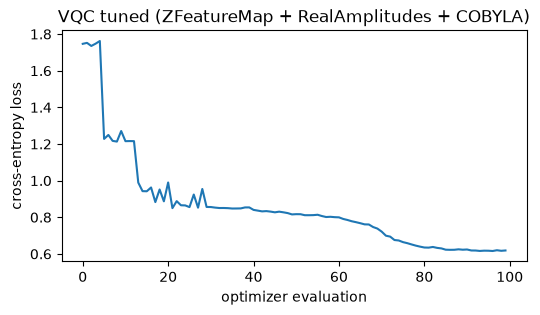

VQC (tuned): ZFeatureMap + RealAmplitudes + COBYLA, maxiter = 100, 300 training flows, 385 s
test F1 (attack = positive): tuned = 0.7928 | default ZZ + RealAmplitudes + COBYLA = 0.5761


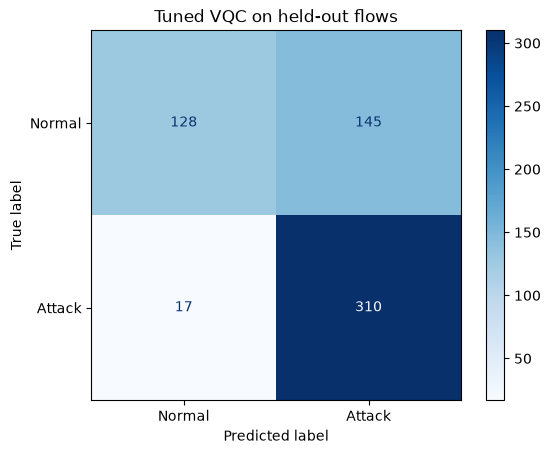

In [16]:
# Retrain the winning configuration on the full training sample, then evaluate once on the test sample
if BEST.optimizer in GRAD_OPTS:
    # CHOICE: parameter-shift gradients cost 2 x (trainable angles) circuits per flow per step, so a gradient optimizer
    # is retrained on a subset of the training flows with the GRAD budget
    n_final, final_maxiter = min(N_TRAIN, 4 * GRAD_TRAIN), GRAD_MAXITER
else:
    n_final, final_maxiter = N_TRAIN, VQC_MAXITER
algorithm_globals.random_seed = SEED
cb, hist_best = make_live_plot(f"VQC tuned ({BEST.feature_map} + {BEST.ansatz} + {BEST.optimizer})")
vqc_best = make_vqc(*BEST, final_maxiter, callback=cb)
t0 = time.time(); vqc_best.fit(X_train[:n_final], y_train[:n_final]); y_pred_best = vqc_best.predict(X_test); t_best = time.time() - t0   # X_train is already shuffled

print(f"VQC (tuned): {BEST.feature_map} + {BEST.ansatz} + {BEST.optimizer}, maxiter = {final_maxiter}, {n_final} training flows, {t_best:.0f} s")
print(f"test F1 (attack = positive): tuned = {f1_score(y_test, y_pred_best):.4f} | default ZZ + RealAmplitudes + COBYLA = {f1_score(y_test, y_pred_vqc):.4f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best), display_labels=["Normal", "Attack"]).plot(cmap="Blues")
plt.title("Tuned VQC on held-out flows"); plt.show()

## 5c. Quantum support vector machine (QSVM)

The QSVM replaces the trainable ansatz by a kernel. Two flows are compared through the overlap of their encoded states,

$$k(a, b) = \left|\langle \phi(a) | \phi(b) \rangle\right|^2,$$

and a classical SVM (scikit-learn's `SVC` with `kernel="precomputed"`, wrapped by Qiskit's `QSVC`) finds the separating hyperplane in that feature space. Nothing is optimised on the quantum side. `FidelityStatevectorKernel` computes the overlaps exactly from statevectors (a noiseless stand-in for the paper's device runs).

Three things are chosen on the **validation split of the training sample**: the feature map (the best map of Section 5b with RealAmplitudes + COBYLA, RawFeatureVector excluded because with 4 normalised features its overlap is just a squared cosine similarity, which a classical kernel already provides), the **kernel bandwidth** (the angles are multiplied by a scale before encoding) and the SVM's `C`. The cell also recomputes a corner of the kernel matrix by hand from `Statevector` objects, so there is nothing hidden in the library call.

kernel feature map: ZFeatureMap | validation F1 per map: {'ZFeatureMap': 83.33, 'ZZFeatureMap': 60.87, 'PauliFeatureMap': 69.23}


validation F1 (%) per (bandwidth, C): {(0.5, 1.0): 85.98, (0.5, 10.0): 87.62, (1.0, 1.0): 86.79, (1.0, 10.0): 88.0, (2.0, 1.0): 83.17, (2.0, 10.0): 82.0} -> (1.0, 10.0)


QSVC (bandwidth 1.0, C 10.0): test F1 (attack = positive) = 0.8264 (9.4 s for training and prediction) | untuned (bandwidth 1, C 1): 0.8175


hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel: True


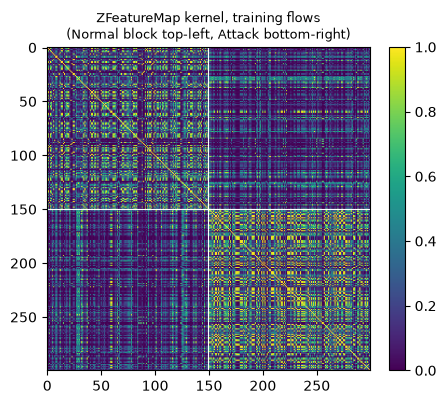

In [17]:
# CHOICE: best feature map on the validation split (RealAmplitudes + COBYLA stage), RawFeatureVector excluded
fm_scores = {c.feature_map: r["val F1 (%)"] for c, r in grid_results.items()
             if c.ansatz == "RealAmplitudes" and c.optimizer == "COBYLA" and c.feature_map != "RawFeatureVector"}
kernel_fm_name = max(fm_scores, key=fm_scores.get) if fm_scores else "ZZFeatureMap"
print("kernel feature map:", kernel_fm_name, "| validation F1 per map:", fm_scores)

def make_qsvc(bw, C, fm_name=None):
    return QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=build_feature_map(fm_name or kernel_fm_name)), C=C, random_state=SEED)

# bandwidth and C on the validation split of the training sample (test flows untouched)
qsvc_val = {}
for bw, C in product(BANDWIDTHS, C_GRID):
    m = make_qsvc(bw, C).fit(bw * Xg_tr, yg_tr)
    qsvc_val[(bw, C)] = 100 * f1_score(yg_val, m.predict(bw * Xg_val))
BW, C_BEST = max(qsvc_val, key=qsvc_val.get)
print("validation F1 (%) per (bandwidth, C):", {k: round(v, 2) for k, v in qsvc_val.items()}, "->", (BW, C_BEST))

t0 = time.time()
qsvc = make_qsvc(BW, C_BEST).fit(BW * X_train, y_train); y_pred_qsvc = qsvc.predict(BW * X_test); t_qsvc = time.time() - t0
y_pred_qsvc_default = make_qsvc(1.0, 1.0).fit(X_train, y_train).predict(X_test)
print(f"QSVC (bandwidth {BW}, C {C_BEST}): test F1 (attack = positive) = {f1_score(y_test, y_pred_qsvc):.4f} "
      f"({t_qsvc:.1f} s for training and prediction) | untuned (bandwidth 1, C 1): {f1_score(y_test, y_pred_qsvc_default):.4f}")

# Cross-check: the same kernel entries computed by hand from statevectors
qkernel = FidelityStatevectorKernel(feature_map=build_feature_map(kernel_fm_name))
K_train = qkernel.evaluate(BW * X_train)
fm_k = build_feature_map(kernel_fm_name)
states = [Statevector(fm_k.assign_parameters(x)) for x in BW * X_train[:20]]
K_hand = np.abs(np.array([[a.inner(b) for b in states] for a in states])) ** 2
print("hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel:", np.allclose(K_hand, K_train[:20, :20], atol=1e-6))

order = np.argsort(y_train, kind="stable")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(K_train[order][:, order], cmap="viridis", vmin=0, vmax=1)
ax.axhline((y_train == 0).sum() - .5, color="w", lw=.8); ax.axvline((y_train == 0).sum() - .5, color="w", lw=.8)
ax.set_title(f"{kernel_fm_name} kernel, training flows\n(Normal block top-left, Attack bottom-right)", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.show()

## 5d. Quantum convolutional neural network

The QCNN follows the construction in Qiskit's QCNN tutorial (after Cong, Choi and Lukin, *Nature Physics*, 2019). A convolution layer applies the same parametrised two-qubit block to neighbouring pairs; a pooling layer then folds half of the qubits into the other half. With 4 qubits the circuit runs conv -> pool (4 -> 2) -> conv -> pool (2 -> 1), and the class is read from $\langle Z\rangle$ on the last remaining qubit: positive means Normal, negative means Attack after mapping labels to $\pm 1$ (the sign convention is learned: the training labels are $+1$ for attack and $-1$ for normal and the prediction is the sign of the output). The ZZ feature map encodes the 4 angles (`# CHOICE`; the paper's Fig. 1c only says "feature encoding").

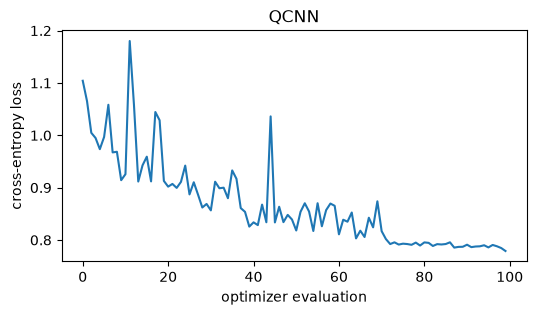

QCNN: test F1 (attack = positive) = 0.6629 (486 s for training and prediction)


In [18]:
def conv_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1)
    qc.cx(0, 1); qc.ry(p[2], 1); qc.cx(1, 0); qc.rz(np.pi / 2, 0)
    return qc

def pool_block(p):
    qc = QuantumCircuit(2)
    qc.rz(-np.pi / 2, 1); qc.cx(1, 0); qc.rz(p[0], 0); qc.ry(p[1], 1); qc.cx(0, 1); qc.ry(p[2], 1)
    return qc

def conv_layer(n, prefix):
    q = list(range(n))
    pairs = [(0, 1)] if n == 2 else list(zip(q[0::2], q[1::2])) + list(zip(q[1::2], q[2::2] + [0]))
    params = ParameterVector(prefix, 3 * len(pairs)); qc = QuantumCircuit(n)
    for k, (a, b) in enumerate(pairs):
        qc.compose(conv_block(params[3 * k:3 * k + 3]), [a, b], inplace=True)
    qc.barrier(); return qc

def pool_layer(n, prefix):
    half = n // 2; params = ParameterVector(prefix, 3 * half); qc = QuantumCircuit(n)
    for k, (src, sink) in enumerate(zip(range(half), range(half, n))):
        qc.compose(pool_block(params[3 * k:3 * k + 3]), [src, sink], inplace=True)
    qc.barrier(); return qc

def qcnn_circuit(n=N_QUBITS):
    assert n & (n - 1) == 0, "QCNN pooling halves the register, so N_QUBITS must be a power of two"
    ansatz = QuantumCircuit(n); active = list(range(n)); layer = 1
    while len(active) > 1:
        ansatz.compose(conv_layer(len(active), f"c{layer}"), active, inplace=True)
        ansatz.compose(pool_layer(len(active), f"p{layer}"), active, inplace=True)
        active = active[len(active) // 2:]; layer += 1
    fm = build_feature_map("ZZFeatureMap", n)                 # CHOICE: QCNN feature map
    circuit = fm.compose(ansatz)
    observable = SparsePauliOp.from_sparse_list([("Z", [active[0]], 1.0)], num_qubits=n)
    return circuit, fm, ansatz, observable

def make_qcnn(maxiter, callback=None):
    circuit, fm, ansatz, obs = qcnn_circuit()
    qnn = EstimatorQNN(circuit=circuit, observables=obs, input_params=fm.parameters,
                       weight_params=ansatz.parameters, estimator=StatevectorEstimator())
    return NeuralNetworkClassifier(qnn, optimizer=COBYLA(maxiter=maxiter), callback=callback)

algorithm_globals.random_seed = SEED
cb, hist = make_live_plot("QCNN")
qcnn = make_qcnn(QCNN_MAXITER, callback=cb)
t0 = time.time(); qcnn.fit(X_train, 2 * y_train - 1); y_pred_qcnn = (np.ravel(qcnn.predict(X_test)) > 0).astype(int); t_qcnn = time.time() - t0     # labels as -1 / +1
print(f"QCNN: test F1 (attack = positive) = {f1_score(y_test, y_pred_qcnn):.4f} ({t_qcnn:.0f} s for training and prediction)")

## 5e. Classical baselines

The paper compares against a random forest and an SVM from scikit-learn and a CNN in TensorFlow. Each baseline is trained twice:

- on the same 4 PCA angles the quantum models see, which isolates the effect of the model;
- on all standardised flow features (the one-hot and `log1p` encoding of Section 2), which is what a practitioner would deploy.

The paper does not say which input its baselines used. Reporting both keeps the comparison honest.

In [19]:
def cnn_classifier(n_features, n_classes):
    # CHOICE: small 1-D CNN; the paper does not give its architecture
    out, loss = (1, "binary_crossentropy") if n_classes == 2 else (n_classes, "sparse_categorical_crossentropy")
    model = tf.keras.Sequential([
        tf.keras.layers.Input((n_features, 1)),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Conv1D(16, 2, padding="same", activation="relu"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(out, activation="sigmoid" if n_classes == 2 else "softmax")])
    model.compile(optimizer="adam", loss=loss)
    return model

def run_classical(Xtr, ytr, Xte, n_classes=2, seed=SEED):
    preds = {}
    preds["RF"]  = RandomForestClassifier(n_estimators=200, random_state=seed).fit(Xtr, ytr).predict(Xte)
    preds["SVM"] = SVC(kernel="rbf", random_state=seed).fit(Xtr, ytr).predict(Xte)
    tf.random.set_seed(seed)
    cnn = cnn_classifier(Xtr.shape[1], n_classes)
    cnn.fit(Xtr[..., None], ytr, epochs=CNN_EPOCHS, batch_size=32, verbose=0)
    p = cnn.predict(Xte[..., None], verbose=0)
    preds["CNN"] = (p.ravel() > 0.5).astype(int) if n_classes == 2 else p.argmax(1)
    return preds

t0 = time.time()
classic_q = run_classical(X_train, y_train, X_test)                       # same 4 angles
classic_full = run_classical(B["S_train"], y_train, B["S_test"])          # all standardised features
t_classic = time.time() - t0
for k in classic_q:
    print(f"{k:4s} F1 on 4 PCA angles = {f1_score(y_test, classic_q[k]):.4f} | on all {B['S_train'].shape[1]} encoded features = {f1_score(y_test, classic_full[k]):.4f}")
print(f"classical baselines took {t_classic:.0f} s")

RF   F1 on 4 PCA angles = 0.8354 | on all 56 encoded features = 0.8753
SVM  F1 on 4 PCA angles = 0.8132 | on all 56 encoded features = 0.8329
CNN  F1 on 4 PCA angles = 0.7789 | on all 56 encoded features = 0.8624
classical baselines took 75 s


## Quantum Circuit Architecture

This section draws the circuits that the cells above actually build and run, with qubit count, depth and trainable-parameter count for each. The first part shows the building blocks of the paper's 4 x 4 grid (Table I), the second part the trained models: the default VQC, the tuned VQC, the QSVM kernel circuit, the QCNN, and the VQC after transpilation to a (fake) IBM device. Circuit details that the paper omits are listed at the end of the section.

### Building blocks of the paper's grid: four feature maps and four ansätze

Feature map ZFeatureMap: 4 qubits | depth 4 (decomposed to basic gates) | 4 parameters (data inputs) | gates {'u': 16}


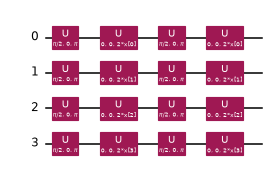

Feature map ZZFeatureMap: 4 qubits | depth 19 (decomposed to basic gates) | 4 parameters (data inputs) | gates {'u': 22, 'cx': 12}


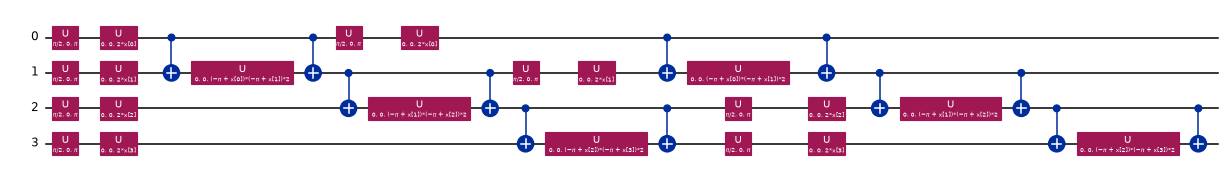

Feature map PauliFeatureMap: 4 qubits | depth 43 (decomposed to basic gates) | 4 parameters (data inputs) | gates {'u': 76, 'cx': 24}


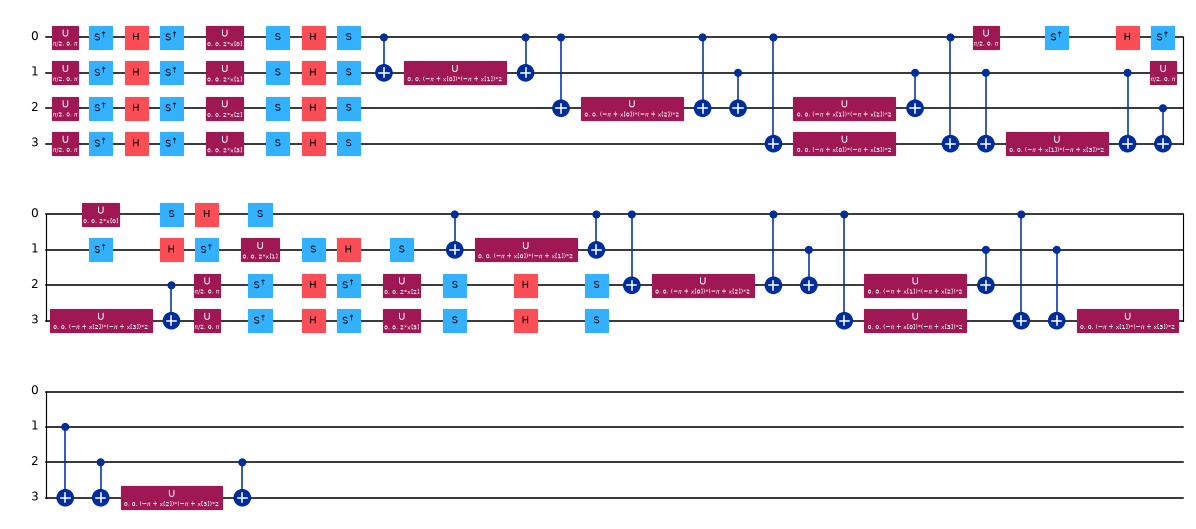

Feature map RawFeatureVector: 2 qubits | depth 1 (decomposed to basic gates) | 4 parameters (data inputs) | gates {'ParameterizedInitialize': 1}


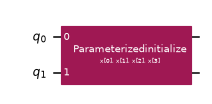

In [20]:
def flat_of(qc):
    # decompose to basic gates; RawFeatureVector's ParameterizedInitialize cannot be decomposed with unbound parameters, so keep it as one box
    try:
        return qc.decompose(reps=3)
    except Exception:
        return qc

def draw(qc, scale=0.5, decompose=True):
    # one line when short, wrapped every 32 columns when long
    c = qc.decompose() if decompose else qc
    return c.draw("mpl", fold=-1 if c.depth() <= 32 else 32, scale=scale)

def describe(name, qc, extra=""):
    flat = flat_of(qc)
    ops = {k: v for k, v in flat.count_ops().items() if k not in ("barrier",)}
    print(f"{name}: {qc.num_qubits} qubits | depth {flat.depth()} (decomposed to basic gates) | {qc.num_parameters} parameters {extra}| gates {ops}")

for name in FEATURE_MAPS:
    fm = build_feature_map(name)
    describe(f"Feature map {name}", fm, "(data inputs) ")
    display(draw(fm, 0.55, decompose=(name != "RawFeatureVector")))

Ansatz RealAmplitudes: 4 qubits | depth 8 (decomposed to basic gates) | 12 parameters (trainable) | gates {'u': 12, 'cx': 6}


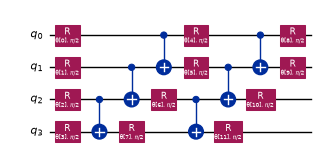

Ansatz EfficientSU2: 4 qubits | depth 11 (decomposed to basic gates) | 24 parameters (trainable) | gates {'u': 24, 'cx': 6}


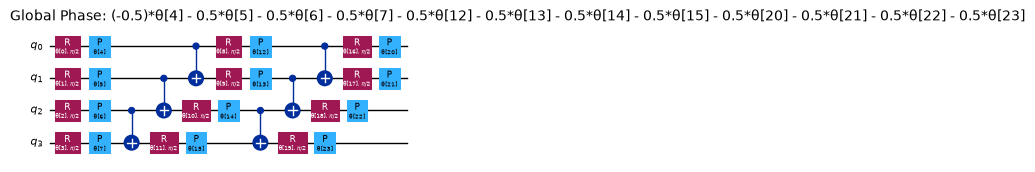

Ansatz ExcitationPreserving: 4 qubits | depth 77 (decomposed to basic gates) | 24 parameters (trainable) | gates {'u': 156, 'cx': 24}


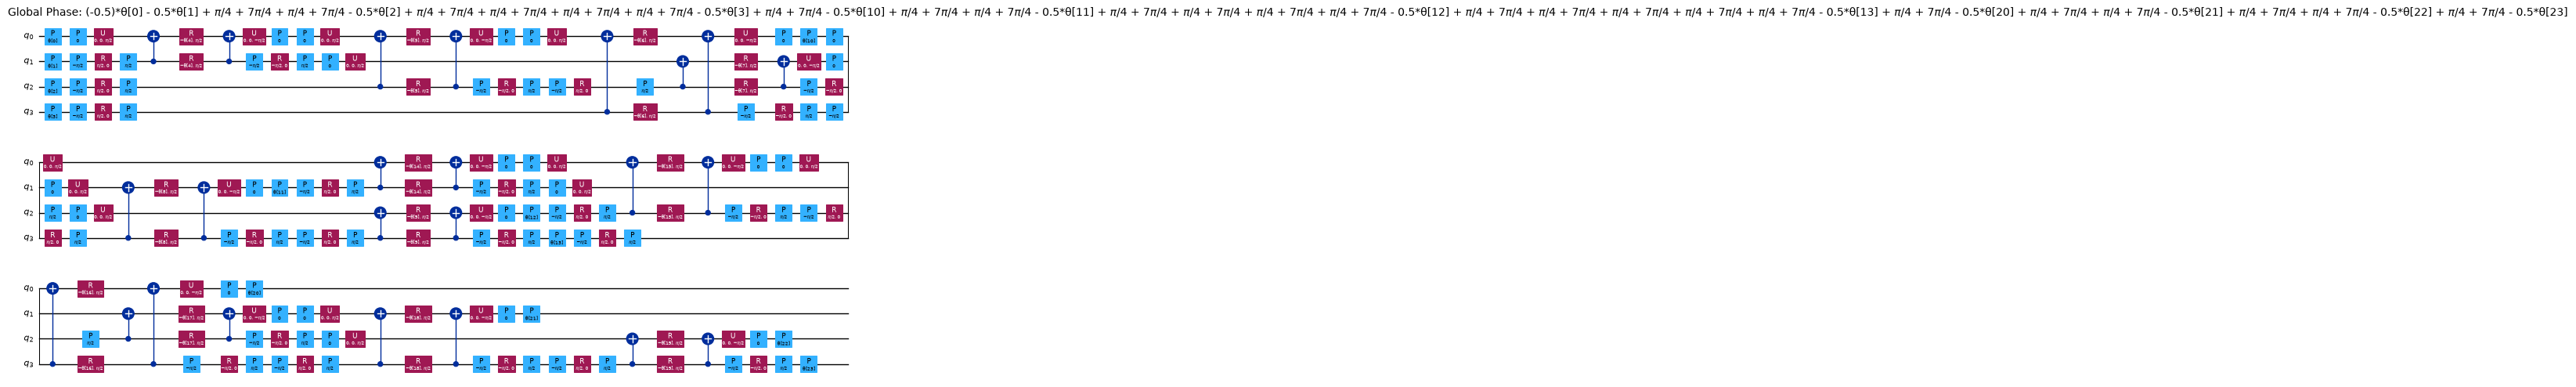

Ansatz TwoLocal: 4 qubits | depth 26 (decomposed to basic gates) | 24 parameters (trainable) | gates {'u': 48, 'cx': 12}


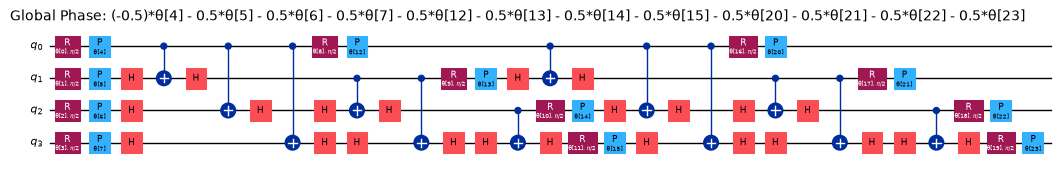

In [21]:
for name in ANSATZE:
    an = build_ansatz(name, N_QUBITS)
    describe(f"Ansatz {name}", an, "(trainable) ")
    display(draw(an, 0.5))

### The trained VQC circuits (default and tuned)

default VQC ('ZZFeatureMap', 'RealAmplitudes', 'COBYLA'): 4 qubits | depth 28 | 4 input parameters (flow angles) + 12 trainable weights


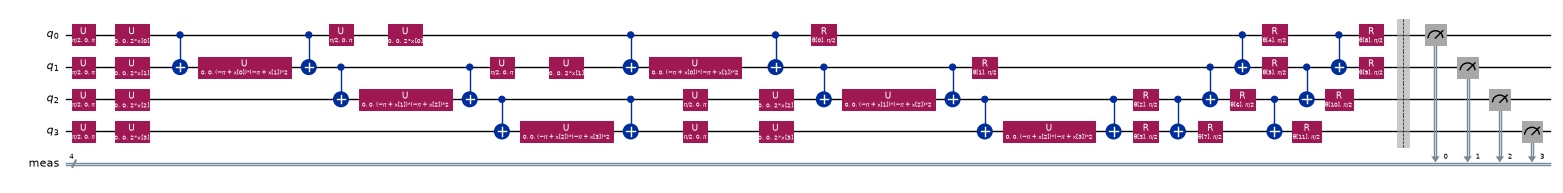

tuned VQC ('ZFeatureMap', 'RealAmplitudes', 'COBYLA'): 4 qubits | depth 13 | 4 input parameters (flow angles) + 12 trainable weights


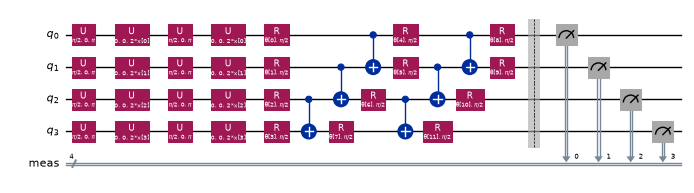

In [22]:
def vqc_executed_circuit(model):
    # The circuit the sampler runs: feature map + ansatz + measurement of every qubit
    c = model.neural_network.circuit.copy(); c.measure_all()
    return c

for label, model, cfg in [("default VQC", vqc, ("ZZFeatureMap", "RealAmplitudes", "COBYLA")), ("tuned VQC", vqc_best, tuple(BEST))]:
    c = vqc_executed_circuit(model)
    n_inputs, n_weights = len(model.feature_map.parameters), len(model.weights)
    print(f"{label} {cfg}: {c.num_qubits} qubits | depth {flat_of(c).depth()} | {n_inputs} input parameters (flow angles) + {n_weights} trainable weights")
    display(draw(c, 0.5, decompose=(cfg[0] != "RawFeatureVector")))   # the amplitude-encoding box cannot be expanded with unbound parameters

### The QSVM kernel circuit

`FidelityStatevectorKernel` evaluates $k(a,b)=|\langle\phi(a)|\phi(b)\rangle|^2$ exactly from two statevectors. On hardware the same number is the probability of the all-zero outcome of the compute-uncompute circuit $U_\phi(b)^\dagger U_\phi(a)$. The cell draws that circuit for two real training flows and asserts that its all-zero probability equals the kernel entry used above.

QSVM kernel feature map (ZFeatureMap, bandwidth 1.0): 4 qubits | depth 4 (decomposed to basic gates) | 4 parameters (no trainable parameters) | gates {'u': 16}
compute-uncompute circuit for flows 0 and 1: 4 qubits, depth 8; P(0000) = 0.832782 = kernel entry 0.832782 (asserted equal)


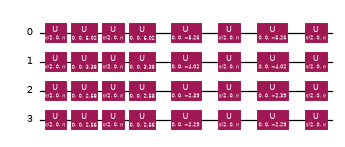

In [23]:
fm_k = build_feature_map(kernel_fm_name)
a, b = BW * X_train[0], BW * X_train[1]
fid = fm_k.assign_parameters(a).compose(fm_k.assign_parameters(b).inverse())
p_zero = abs(Statevector(fid).data[0]) ** 2
k_lib = FidelityStatevectorKernel(feature_map=fm_k).evaluate(np.vstack([a, b]))[0, 1]
assert np.isclose(p_zero, k_lib, atol=1e-8), (p_zero, k_lib)
describe(f"QSVM kernel feature map ({kernel_fm_name}, bandwidth {BW})", fm_k, "(no trainable parameters) ")
print(f"compute-uncompute circuit for flows 0 and 1: {fid.num_qubits} qubits, depth {fid.decompose(reps=3).depth()}; "
      f"P(0000) = {p_zero:.6f} = kernel entry {k_lib:.6f} (asserted equal)")
display(draw(fid, 0.45))

### The QCNN circuit

QCNN: 4 qubits | depth 50 | 4 input parameters + 24 trainable weights (conv + pool)
read-out observable: ZIII (<Z> on the last remaining qubit; no mid-circuit measurement is simulated: the pooled qubits are traced out exactly)


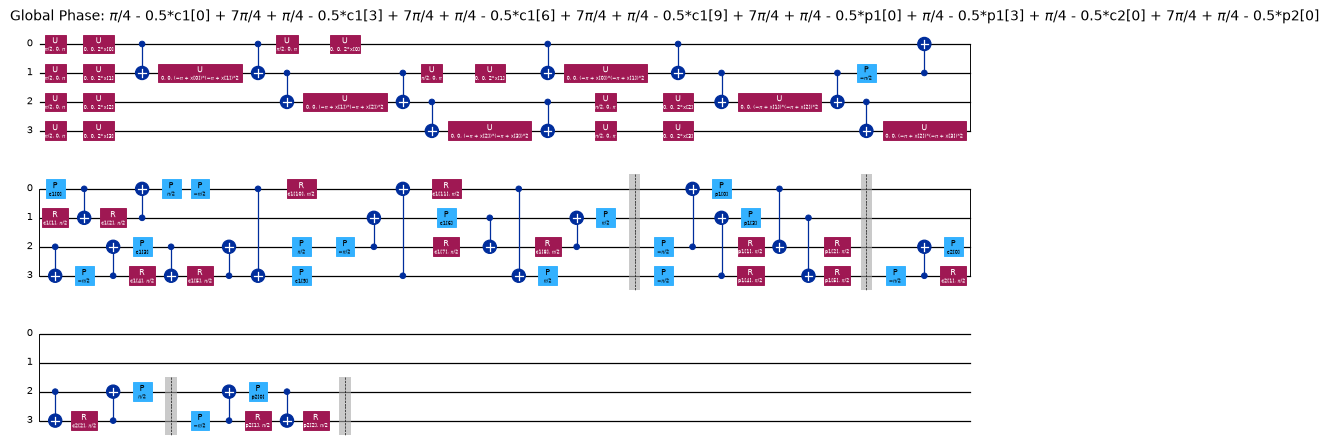

In [24]:
circ_q, fm_q, ans_q, obs_q = qcnn_circuit()
# the weights the model was trained with can be bound to the same circuit
bound = circ_q.assign_parameters({**dict(zip(fm_q.parameters, X_train[0])), **dict(zip(ans_q.parameters, qcnn.weights))})
print(f"QCNN: {circ_q.num_qubits} qubits | depth {circ_q.decompose(reps=3).depth()} | {len(fm_q.parameters)} input parameters + {len(ans_q.parameters)} trainable weights (conv + pool)")
print("read-out observable:", obs_q.paulis[0], "(<Z> on the last remaining qubit; no mid-circuit measurement is simulated: the pooled qubits are traced out exactly)")
display(draw(circ_q, 0.45))

### The VQC after transpilation to an IBM device

The noisy-device study of Section 9 transpiles the VQC to the native gates and the coupling map of each of the paper's five devices (Qiskit's fake backends). The circuit below is the one that runs there, for IBM Kyoto at optimisation level 3, drawn without the unused qubits of the 127-qubit chip.

tuned VQC (ZFeatureMap + RealAmplitudes) transpiled for fake_kyoto: 4 logical qubits on physical qubits [65, 66, 73, 85] | depth 41 | 6 two-qubit gates | native gates {'rz': 65, 'sx': 44, 'ecr': 6, 'measure': 4, 'barrier': 1}


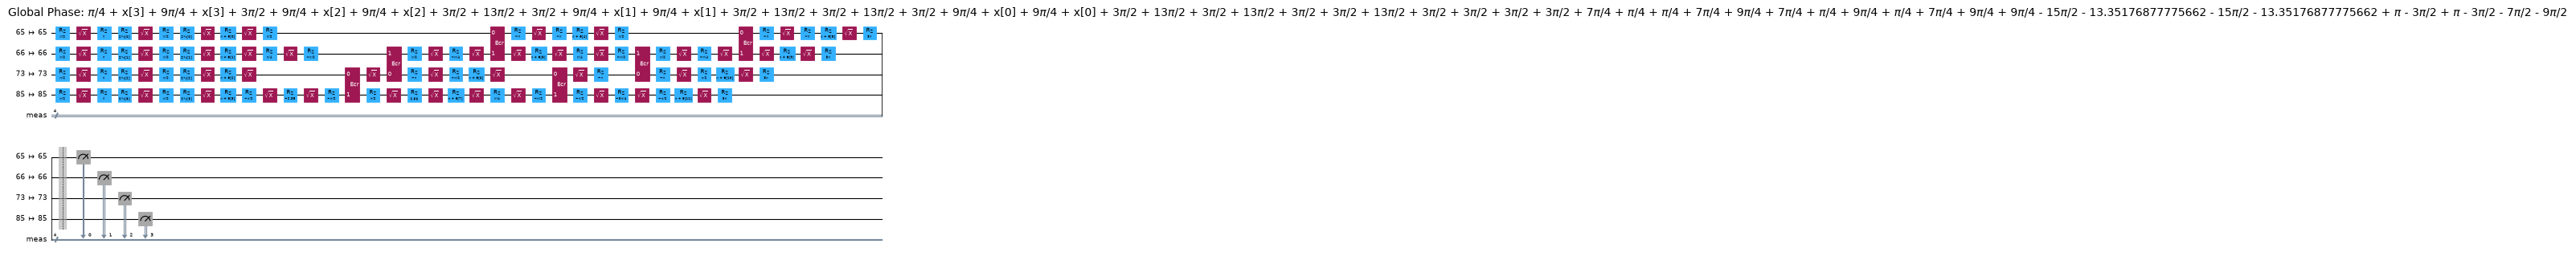

In [25]:
from qiskit_ibm_runtime.fake_provider import FakeCairoV2, FakeKyoto, FakeBrisbane, FakeOsaka, FakeSherbrooke

noisy_model = vqc_best if BEST.feature_map != "RawFeatureVector" else vqc
noisy_name = f"tuned VQC ({BEST.feature_map} + {BEST.ansatz})" if noisy_model is vqc_best else "default VQC (ZZFeatureMap + RealAmplitudes + COBYLA)"
fm_n, an_n = noisy_model.feature_map, noisy_model.ansatz
logical = fm_n.compose(an_n); logical.measure_all()

def device_target(backend):
    # FakeCairoV2's stored calibration lists CX on some couplers and ECR on others, a mix the transpiler
    # cannot orient. For such devices, transpile onto the ECR couplers only; noise still comes from the full snapshot.
    t = backend.target
    if not {"cx", "ecr"} <= set(t.operation_names):
        return t
    reduced = Target(num_qubits=t.num_qubits, dt=t.dt, description=f"{backend.name}, ECR couplers only")
    for name in ["ecr", "rz", "sx", "x", "id", "measure", "delay", "reset"]:
        if name in t.operation_names:
            reduced.add_instruction(t.operation_from_name(name), dict(t[name]), name=name)
    return reduced

kyoto = FakeKyoto()
isa_kyoto = generate_preset_pass_manager(optimization_level=3, target=device_target(kyoto), seed_transpiler=SEED).run(logical)
two_q = sum(v for k, v in isa_kyoto.count_ops().items() if k in ("ecr", "cz", "cx"))
print(f"{noisy_name} transpiled for {kyoto.name}: {logical.num_qubits} logical qubits on physical qubits {isa_kyoto.layout.final_index_layout()[:logical.num_qubits]} | depth {isa_kyoto.depth()} | "
      f"{two_q} two-qubit gates | native gates {dict(isa_kyoto.count_ops())}")
display(isa_kyoto.draw("mpl", idle_wires=False, fold=40, scale=0.4))

### Circuit assumptions where the paper is silent

- **Qubits and encoding.** Fig. 1 of the paper shows 4 qubits; each flow is reduced to 4 PCA angles, one per qubit. Only the amplitude-encoding map (`RawFeatureVector`) uses 2 qubits.
- **Feature-map repetitions and Pauli strings.** Fig. 1a shows a `ZFeatureMap` with two repetitions (`H`, `P(2x)`), which is what is used. The paper does not give the Pauli strings of `PauliFeatureMap`; `["Y", "ZZ"]` is a choice. `ZZFeatureMap` uses linear entanglement.
- **Ansatz depth.** Fig. 1b shows 12 `RY` angles on 4 qubits (three `RY` layers), which is `RealAmplitudes` with `reps=2`; the other three ansätze use `reps=2` as well, which is a choice.
- **QCNN.** Fig. 1c only names the blocks (encoding, convolution, pooling); the two-qubit convolution and pooling unitaries are those of the Qiskit QCNN tutorial, the feature map is a ZZ map, and the read-out is $\langle Z\rangle$ on the last qubit.
- **Multiclass.** The multiclass VQC reuses the tuned architecture drawn above; the extra classes only change how the 16 measurement outcomes of the 4 qubits are assigned to classes (`outcome mod 9`). The multiclass QCNN trains nine copies of the QCNN above (one-vs-rest). No new circuit is introduced.
- **Backends.** The paper ran on real IBM devices; here the same circuits run on Aer with noise models built from Qiskit's stored calibration snapshots of those devices.

## 7. Binary results next to the paper (Table IV)

Paper values come from Table IV (UNSW-NB15 column). The paper's classical baselines are trained with default settings and, apparently, on a different input representation than the quantum models. Differences from this notebook are expected: the paper's sample sizes, feature reduction and iteration budgets are unknown, and this run uses a few hundred flows reduced to 4 angles.

Verdict rule: a paper value counts as **reproduced** when the notebook's score on the same 4 angles is within 2 F1 points of it, **exceeded** when it is more than 2 points above and **not reached** when it is more than 2 points below. The paper's ordering claims (quantum above classical, VQC best of the three quantum models) are checked on identical inputs.

,"this notebook, 4 angles (%)","this notebook, all 56 features (%)","paper, Table IV (%)",train+predict time (s),verdict
VQC (default),57.61,NaN,NaN,503.8,
VQC (tuned),79.28,NaN,88.10,385.0,not reached (-8.8)
QSVM,82.64,NaN,87.90,9.4,not reached (-5.3)
QCNN,66.29,NaN,87.32,485.9,not reached (-21.0)
RF,83.54,87.53,82.67,NaN,reproduced
SVM,81.32,83.29,82.34,NaN,reproduced
CNN,77.89,86.24,86.72,NaN,not reached (-8.8)


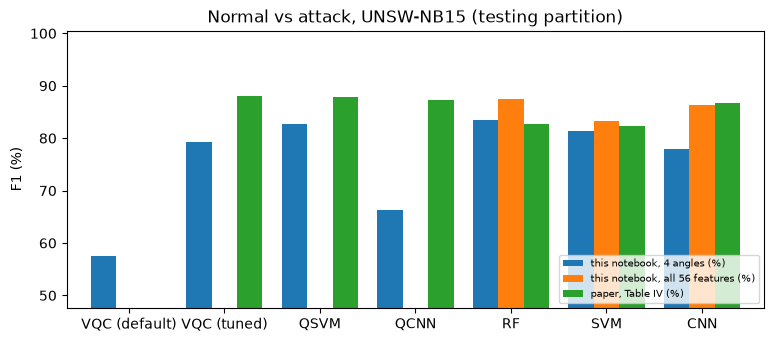

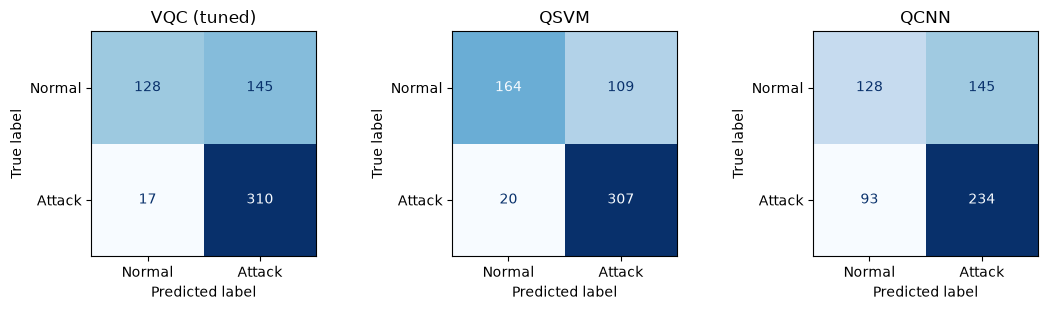

Per-model verdicts (same 4 PCA angles for every model):
  VQC (tuned)  paper  88.10 | notebook  79.28 -> not reached (-8.8)
  QSVM         paper  87.90 | notebook  82.64 -> not reached (-5.3)
  QCNN         paper  87.32 | notebook  66.29 -> not reached (-21.0)
  RF           paper  82.67 | notebook  83.54 -> reproduced
  SVM          paper  82.34 | notebook  81.32 -> reproduced
  CNN          paper  86.72 | notebook  77.89 -> not reached (-8.8)
C2 'QML models beat classical models': every quantum > every classical: False; best quantum 82.64 vs best classical 83.54 -> not reached here
C3 'VQC is the best QML model': VQC (tuned) 79.28, QSVM 82.64, QCNN 66.29 -> not reached here


In [26]:
PAPER_BINARY_UNSW = {"VQC (tuned)": 88.10, "QSVM": 87.90, "QCNN": 87.32, "RF": 82.67, "SVM": 82.34, "CNN": 86.72}   # QML-IDS Table IV, UNSW-NB15

def verdict(ours, paper, tol=2.0):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})")

f1 = lambda p: 100 * f1_score(y_test, p)
ours4 = {"VQC (default)": f1(y_pred_vqc), "VQC (tuned)": f1(y_pred_best), "QSVM": f1(y_pred_qsvc), "QCNN": f1(y_pred_qcnn),
         **{k: f1(v) for k, v in classic_q.items()}}
binary = pd.DataFrame({
    "this notebook, 4 angles (%)": ours4,
    f"this notebook, all {B['S_train'].shape[1]} features (%)": {k: f1(v) for k, v in classic_full.items()},
    "paper, Table IV (%)": PAPER_BINARY_UNSW,
}).round(2)
binary["train+predict time (s)"] = pd.Series({"VQC (default)": t_vqc, "VQC (tuned)": t_best, "QSVM": t_qsvc, "QCNN": t_qcnn}).round(1)
binary["verdict"] = [verdict(ours4[m], PAPER_BINARY_UNSW[m]) if m in PAPER_BINARY_UNSW else "" for m in binary.index]
display(binary)

ax = binary.iloc[:, :3].plot.bar(figsize=(9, 3.6), rot=0, width=.8); ax.set_ylabel("F1 (%)")
ax.set_ylim(max(0, np.nanmin(binary.iloc[:, :3].values) - 10), 100.5); ax.legend(loc="lower right", fontsize=7)
ax.set_title("Normal vs attack, UNSW-NB15 (testing partition)"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
for a_, (name, p) in zip(axs, [("VQC (tuned)", y_pred_best), ("QSVM", y_pred_qsvc), ("QCNN", y_pred_qcnn)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Normal", "Attack"]).plot(ax=a_, cmap="Blues", colorbar=False)
    a_.set_title(name)
plt.tight_layout(); plt.show()

qml3 = ["VQC (tuned)", "QSVM", "QCNN"]; cls3 = ["RF", "SVM", "CNN"]
best_q = max(ours4[k] for k in qml3); best_c = max(ours4[k] for k in cls3)
c2_all = all(ours4[q] > ours4[c] for q in qml3 for c in cls3)
c2_best = best_q > best_c
c3 = ours4["VQC (tuned)"] >= max(ours4["QSVM"], ours4["QCNN"])
print("Per-model verdicts (same 4 PCA angles for every model):")
for m, p in PAPER_BINARY_UNSW.items():
    print(f"  {m:12s} paper {p:6.2f} | notebook {ours4[m]:6.2f} -> {verdict(ours4[m], p)}")
print(f"C2 'QML models beat classical models': every quantum > every classical: {c2_all}; best quantum {best_q:.2f} vs best classical {best_c:.2f} -> "
      + ("reproduced" if c2_all else ("partly (best quantum above best classical)" if c2_best else "not reached here")))
print(f"C3 'VQC is the best QML model': VQC (tuned) {ours4['VQC (tuned)']:.2f}, QSVM {ours4['QSVM']:.2f}, QCNN {ours4['QCNN']:.2f} -> {'reproduced' if c3 else 'not reached here'}")

## 8. Repeating the binary comparison over several seeds

A single seed says little at a few hundred flows. This section redraws the training and test samples with each seed in `SEEDS`, refits the whole preprocessing on the new training sample and repeats the **cheap** models: QSVM (feature map, bandwidth and `C` fixed from the validation split above), RF, SVM and CNN on the 4 angles. The VQCs and the QCNN are not repeated because their training budget is the dominant cost (`# CHOICE`); the single-seed gap between the VQC and the other models should be read with the seed-to-seed spread of the repeated models in mind. Mean and standard deviation of F1 are reported.

seed 42 {'QSVM': 82.64, 'RF': 83.54, 'SVM': 81.32, 'CNN': 78.45}


seed 43 {'QSVM': 87.25, 'RF': 81.83, 'SVM': 80.05, 'CNN': 74.22}


seed 44 {'QSVM': 84.03, 'RF': 84.09, 'SVM': 84.78, 'CNN': 82.28}


3 seeds: [42, 43, 44]


,mean F1 (%),std,paper Table IV (%),verdict on mean
QSVM,84.64,1.93,87.90,not reached (-3.3)
RF,83.15,0.96,82.67,reproduced
SVM,82.05,2.00,82.34,reproduced
CNN,78.32,3.29,86.72,not reached (-8.4)


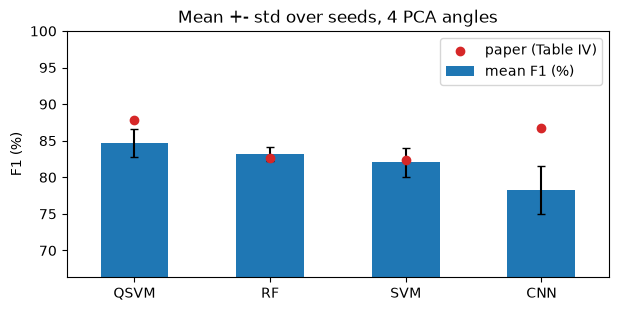

In [27]:
seed_rows = []
for sd in SEEDS:
    D = draw_binary(sd)
    Xa, Xb, ya, yb = D["X_train"], D["X_test"], D["y_train"], D["y_test"]
    row = {"seed": sd}
    row["QSVM"] = 100 * f1_score(yb, make_qsvc(BW, C_BEST).fit(BW * Xa, ya).predict(BW * Xb))
    cl = run_classical(Xa, ya, Xb, seed=sd)
    for k in cl: row[k] = 100 * f1_score(yb, cl[k])
    seed_rows.append(row); print("seed", sd, {k: round(v, 2) for k, v in row.items() if k != "seed"}, flush=True)
algorithm_globals.random_seed = SEED
seed_df = pd.DataFrame(seed_rows).set_index("seed")
summary = pd.DataFrame({"mean F1 (%)": seed_df.mean(), "std": seed_df.std(ddof=0)}).round(2)
summary["paper Table IV (%)"] = pd.Series(PAPER_BINARY_UNSW)
summary["verdict on mean"] = [verdict(summary.loc[m, "mean F1 (%)"], summary.loc[m, "paper Table IV (%)"]) for m in summary.index]
print(f"{len(SEEDS)} seeds: {SEEDS}")
display(summary)
ax = summary["mean F1 (%)"].plot.bar(yerr=summary["std"], figsize=(7, 3.2), rot=0, capsize=3, color="tab:blue")
ax.scatter(range(len(summary)), summary["paper Table IV (%)"], color="tab:red", zorder=3, label="paper (Table IV)"); ax.legend()
ax.set_ylabel("F1 (%)"); ax.set_ylim(max(0, summary["mean F1 (%)"].min() - 12), 100); ax.set_title("Mean +- std over seeds, 4 PCA angles"); plt.show()

## 9. From simulator to NISQ devices (paper Tables II-III, UNSW-NB15 rows)

The paper re-ran its models on five IBM devices (Cairo, Kyoto, Brisbane, Osaka, Sherbrooke) with transpiler optimisation levels 0-3, two Runtime resilience levels and dynamical decoupling on or off. Most of those machines have since been retired, so this section uses Qiskit's *fake* versions of the same five devices: each one carries a stored snapshot of that device's qubit layout, native gates, gate errors, readout errors and coherence times, and Aer turns the snapshot into a noise model.

The trained VQC weights are kept fixed; only inference runs on the noisy devices (the paper's training on hardware is not simulated; QSVM and QCNN device runs are not repeated here and are reported as *cannot be checked*). For each device the cell measures test F1 under:

- **optimisation levels 0-3**: how hard the transpiler works to shorten the circuit after mapping it onto the device's qubit graph and native gates;
- **dynamical decoupling (DD)**: X-X pulse pairs inserted into idle periods to refocus dephasing;
- **readout correction (RO)**: inverting each qubit's measured confusion matrix. On IBM Runtime the Estimator's `resilience_level=1` applies a related readout technique (TREX); the paper's resilience setting is approximated here, not reproduced.

model run under device noise: tuned VQC (ZFeatureMap + RealAmplitudes)


ibm_cairo done


ibm_kyoto done


ibm_brisbane done


ibm_osaka done


ibm_sherbrooke done


noiseless Aer simulator, same 100 flows: F1 = 76.80 % (paper QASM VQC: 88.56 %)


,opt 0,opt 1,opt 2,opt 3,depth (opt 3),2q gates (opt 3),opt 3 + DD,opt 3 + DD + RO,"paper VQC, Tables II-III (%)"
device,,,,,,,,,
ibm_cairo,76.8,76.80,76.80,76.80,35,6,76.80,76.80,87.91
ibm_kyoto,43.3,45.83,49.54,48.15,41,6,48.15,48.15,88.10
ibm_brisbane,76.8,76.80,77.42,77.42,42,6,77.42,77.42,85.78
ibm_osaka,76.8,76.80,76.80,76.80,45,6,76.80,76.80,87.75
ibm_sherbrooke,76.8,76.80,76.80,76.80,30,6,76.80,76.80,87.31


noisy-device F1 range over all settings: 43.30 - 77.42 % (best per device: {'ibm_cairo': 76.8, 'ibm_kyoto': 49.54, 'ibm_brisbane': 77.42, 'ibm_osaka': 76.8, 'ibm_sherbrooke': 76.8})


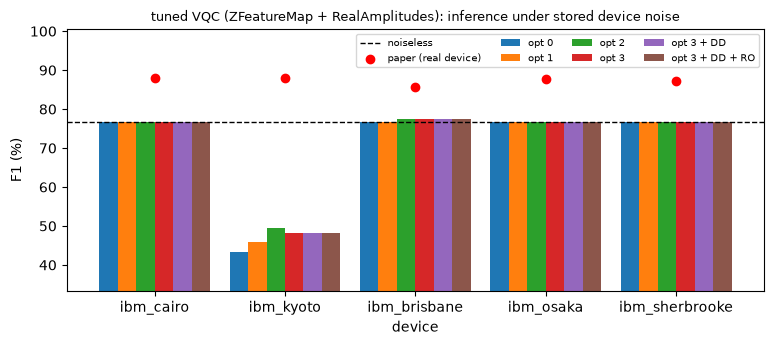

In [28]:
print("model run under device noise:", noisy_name)
Xn, yn = X_test[:NOISY_N_TEST], y_test[:NOISY_N_TEST]

def parity_p1(probs):
    # probability of odd parity (class 1) from a 2^n probability vector indexed by bitstring integer
    # Qiskit's VQC assigns outcome integer k to class k % 2 (the value of the qubit-0 bit)
    return probs[np.arange(len(probs)) % 2 == 1].sum()

def readout_matrix(backend, isa):
    # Tensor product of single-qubit confusion matrices for the physical qubits the circuit was mapped to
    phys = isa.layout.final_index_layout()[:fm_n.num_qubits]
    A = np.array([[1.0]])
    for q in phys:                                  # qubit 0 is the least significant bit, so it goes last
        e = backend.target["measure"][(q,)].error or 0.0
        A = np.kron(np.array([[1 - e, e], [e, 1 - e]]), A)
    return A

SAMPLERS = {}

def noisy_f1(backend, opt_level, dd=False, ro=False):
    target = device_target(backend)
    # Level 0 places virtual qubit i on physical qubit i. On devices whose stored calibration marks some
    # couplers as broken, qubits 0..3 are not connected, so level 0 then reuses the level-1 placement.
    try:
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED)
        pm.run(logical)
    except Exception:
        layout = generate_preset_pass_manager(optimization_level=1, target=target, seed_transpiler=SEED).run(logical).layout
        pm = generate_preset_pass_manager(optimization_level=opt_level, target=target, seed_transpiler=SEED,
                                          initial_layout=layout.initial_index_layout()[:logical.num_qubits])
    if dd:
        pm.scheduling = PassManager([ALAPScheduleAnalysis(target=target),
                                     PadDynamicalDecoupling(target=target, dd_sequence=[XGate(), XGate()])])
    isa = pm.run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    if backend.name not in SAMPLERS:                      # building the 127-qubit noise model is the slow, memory-hungry step: do it once per device
        SAMPLERS[backend.name] = AerSampler.from_backend(backend, default_shots=SHOTS, seed=SEED)
    data = SAMPLERS[backend.name].run([(isa, binds)]).result()[0].data.meas
    A_inv = np.linalg.pinv(readout_matrix(backend, isa)) if ro else None
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts()
        probs = np.zeros(2 ** fm_n.num_qubits)
        for bits, c in counts.items():
            probs[int(bits, 2)] += c
        probs /= probs.sum()
        if ro:
            probs = np.clip(A_inv @ probs, 0, None); probs /= probs.sum()
        preds.append(int(parity_p1(probs) >= 0.5))
    two_q = sum(v for k, v in isa.count_ops().items() if k in ("ecr", "cz", "cx"))
    return 100 * f1_score(yn, preds), isa.depth(), two_q

ideal = 100 * f1_score(yn, noisy_model.predict(Xn))
rows = []
for backend in [FakeCairoV2(), FakeKyoto(), FakeBrisbane(), FakeOsaka(), FakeSherbrooke()]:
    row = {"device": backend.name.replace("fake_", "ibm_")}
    for lvl in range(4):
        row[f"opt {lvl}"], depth, twoq = noisy_f1(backend, lvl)
        if lvl == 3: row["depth (opt 3)"], row["2q gates (opt 3)"] = depth, twoq
    row["opt 3 + DD"] = noisy_f1(backend, 3, dd=True)[0]
    row["opt 3 + DD + RO"] = noisy_f1(backend, 3, dd=True, ro=True)[0]
    rows.append(row); print(row["device"], "done", flush=True)
    SAMPLERS.clear(); gc.collect()

noisy_df = pd.DataFrame(rows).set_index("device").round(2)
PAPER_VQC_DEVICES = {"ibm_cairo": 87.91, "ibm_kyoto": 88.10, "ibm_brisbane": 85.78, "ibm_osaka": 87.75, "ibm_sherbrooke": 87.31}   # QML-IDS Tables II-III, UNSW-NB15 VQC row
noisy_df["paper VQC, Tables II-III (%)"] = pd.Series(PAPER_VQC_DEVICES)
print(f"noiseless Aer simulator, same {len(Xn)} flows: F1 = {ideal:.2f} % (paper QASM VQC: 88.56 %)")
display(noisy_df)
f1_cols = [c for c in noisy_df.columns if c.startswith("opt")]
best_dev = noisy_df[f1_cols].max(axis=1)
print(f"noisy-device F1 range over all settings: {noisy_df[f1_cols].values.min():.2f} - {noisy_df[f1_cols].values.max():.2f} % (best per device: {best_dev.round(2).to_dict()})")
ax = noisy_df[f1_cols].plot.bar(figsize=(9, 3.4), rot=0, width=.85); ax.axhline(ideal, color="k", ls="--", lw=1, label="noiseless")
ax.scatter(range(len(noisy_df)), noisy_df["paper VQC, Tables II-III (%)"], color="red", zorder=4, label="paper (real device)")
ax.set_ylabel("F1 (%)"); ax.set_ylim(max(0, noisy_df[f1_cols].values.min() - 10), 100.5); ax.legend(fontsize=7, ncol=4)
ax.set_title(f"{noisy_name}: inference under stored device noise", fontsize=9); plt.show()

### Optional: the same circuit on a real IBM device

This cell only runs if you paste an IBM Quantum Platform API key into `IBM_TOKEN` in the configuration cell (the open plan includes a monthly free allowance). It sends the test flows as one batched job to the least busy device with dynamical decoupling and measurement twirling switched on. Queue times vary from seconds to hours.

In [29]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as RuntimeSampler
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN, instance=IBM_INSTANCE)
    hw = service.least_busy(operational=True, simulator=False)
    print("running on", hw.name)
    isa = generate_preset_pass_manager(optimization_level=3, backend=hw, seed_transpiler=SEED).run(logical)
    values = {**{p: Xn[:, i] for i, p in enumerate(fm_n.parameters)},
              **{p: np.full(len(Xn), w) for p, w in zip(an_n.parameters, noisy_model.weights)}}
    binds = np.column_stack([values[p] for p in isa.parameters])
    sampler = RuntimeSampler(mode=hw)
    sampler.options.default_shots = SHOTS
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XX"
    sampler.options.twirling.enable_measure = True
    job = sampler.run([(isa, binds)]); print("job id:", job.job_id())
    data = job.result()[0].data.meas
    preds = []
    for i in range(len(Xn)):
        counts = data[i].get_counts(); total = sum(counts.values())
        preds.append(int(sum(c for b, c in counts.items() if int(b, 2) % 2 == 1) / total >= 0.5))
    print(f"{hw.name}: F1 = {100 * f1_score(yn, preds):.2f} %")
else:
    print("IBM_TOKEN is empty; skipping real hardware.")

IBM_TOKEN is empty; skipping real hardware.


In [30]:
# Verdicts for the device claims (C4): VQC per device against Tables II-III. Best opt-level/DD/RO setting per device is used,
# because the paper does not say which transpiler settings produced each cell.
print("C4 per-device VQC F1 (best of the tried settings) vs paper:")
c4_rows = []
for dev, p in PAPER_VQC_DEVICES.items():
    o = best_dev[dev]; c4_rows.append((dev, p, o, verdict(o, p)))
    print(f"  {dev:15s} paper {p:6.2f} | notebook {o:6.2f} -> {verdict(o, p)}")
gap_sim = ideal - best_dev.min()
print(f"  claim 'F1 stays within about 3 points of the simulator on all devices': simulator {ideal:.2f} vs worst device {best_dev.min():.2f} (gap {gap_sim:.1f}) -> "
      + ("reproduced" if gap_sim <= 3 else f"not reached here (gap {gap_sim:.1f} points)"))
print(f"  note: the 3-point claim is relative; the absolute level on this run (simulator {ideal:.2f} %) is compared with the paper in the per-device rows above")
print("  QSVM and QCNN device F1 (Tables II-III): cannot be checked here (devices retired; only the VQC is replayed under noise)")

C4 per-device VQC F1 (best of the tried settings) vs paper:
  ibm_cairo       paper  87.91 | notebook  76.80 -> not reached (-11.1)
  ibm_kyoto       paper  88.10 | notebook  49.54 -> not reached (-38.6)
  ibm_brisbane    paper  85.78 | notebook  77.42 -> not reached (-8.4)
  ibm_osaka       paper  87.75 | notebook  76.80 -> not reached (-11.0)
  ibm_sherbrooke  paper  87.31 | notebook  76.80 -> not reached (-10.5)
  claim 'F1 stays within about 3 points of the simulator on all devices': simulator 76.80 vs worst device 49.54 (gap 27.3) -> not reached here (gap 27.3 points)
  note: the 3-point claim is relative; the absolute level on this run (simulator 76.80 %) is compared with the paper in the per-device rows above
  QSVM and QCNN device F1 (Tables II-III): cannot be checked here (devices retired; only the VQC is replayed under noise)


## 10. Multiclass: which attack is it? (paper Table V)

After detection, the paper classifies the attack family. For UNSW-NB15 it reports per-category F1 for nine families. This section works on the **attack flows only** (the Normal class is not in Table V), with a balanced sample per category from the training partition for fitting and a balanced sample per category from the testing partition for evaluation (Worms has only a few dozen flows in the testing partition, so its F1 is based on very few test flows and will swing between runs).

The VQC handles nine classes the same way it handles two: each 4-bit outcome is assigned to class `outcome mod 9`, so classes 0-6 own two of the 16 outcomes and classes 7-8 only one (a limitation of reading nine classes from four qubits), and the loss is cross-entropy over the nine class probabilities. The QSVM uses scikit-learn's one-vs-one SVM on the precomputed kernel. The QCNN has a single output, so it is trained one-vs-rest (nine binary QCNNs, highest score wins) when `RUN_QCNN_MULTICLASS` is on.

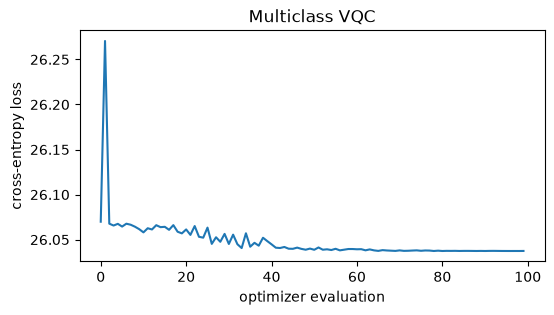

VQC trained in 766 s


QSVM trained in 10 s


In [31]:
if RUN_MULTICLASS:
    Xm_tr, Xm_te, ym_tr, ym_te = M["X_train"], M["X_test"], M["y_train"], M["y_test"]
    print("train", Xm_tr.shape, "test", Xm_te.shape, "| test flows per category:", dict(zip(ATTACKS, np.bincount(ym_te, minlength=9).tolist())))
    mc_pred = {}
    # VQC (same tuned configuration as the binary task). RawFeatureVector encodes 4 features on 2 qubits, whose
    # 4 outcomes cannot index 9 classes, so in that case the kernel feature map (4 qubits, 16 outcomes) is used instead.
    mc_combo = BEST if BEST.feature_map != "RawFeatureVector" else BEST._replace(feature_map=kernel_fm_name)
    mc_n, mc_maxiter = ((len(Xm_tr), MC_VQC_MAXITER) if mc_combo.optimizer not in GRAD_OPTS
                        else (min(len(Xm_tr), 4 * GRAD_TRAIN), GRAD_MAXITER))        # same gradient-budget rule as in 5b
    print("multiclass VQC configuration:", mc_combo, "| maxiter", mc_maxiter, "| training flows", mc_n)
    cb, _ = make_live_plot("Multiclass VQC")
    algorithm_globals.random_seed = SEED
    vqc_mc = make_vqc(mc_combo.feature_map, mc_combo.ansatz, mc_combo.optimizer, mc_maxiter, callback=cb)
    t0 = time.time(); vqc_mc.fit(Xm_tr[:mc_n], ym_tr[:mc_n]); mc_pred["VQC"] = vqc_mc.predict(Xm_te); print(f"VQC trained in {time.time() - t0:.0f} s")

    # QSVM (scikit-learn SVC handles multiclass one-vs-one); same feature map / bandwidth / C as the binary task
    t0 = time.time()
    qsvc_mc = make_qsvc(BW, C_BEST)
    mc_pred["QSVM"] = qsvc_mc.fit(BW * Xm_tr, ym_tr).predict(BW * Xm_te); print(f"QSVM trained in {time.time() - t0:.0f} s")

In [32]:
if RUN_MULTICLASS and RUN_QCNN_MULTICLASS:
    scores = np.zeros((len(Xm_te), len(ATTACKS)))
    for k, fam in enumerate(ATTACKS):
        t0 = time.time()
        algorithm_globals.random_seed = SEED
        m = make_qcnn(MC_QCNN_MAXITER)
        m.fit(Xm_tr, np.where(ym_tr == k, 1, -1))
        scores[:, k] = np.ravel(m.neural_network.forward(Xm_te, m.weights))   # <Z> score, higher = this family
        print(f"QCNN one-vs-rest: {fam} done ({time.time() - t0:.0f} s)", flush=True)
    mc_pred["QCNN"] = scores.argmax(1)

QCNN one-vs-rest: Analysis done (224 s)


QCNN one-vs-rest: Backdoor done (223 s)


QCNN one-vs-rest: DoS done (178 s)


QCNN one-vs-rest: Exploits done (197 s)


QCNN one-vs-rest: Fuzzers done (192 s)


QCNN one-vs-rest: Generic done (141 s)


QCNN one-vs-rest: Reconnaissance done (133 s)


QCNN one-vs-rest: Shellcode done (138 s)


QCNN one-vs-rest: Worms done (128 s)


In [33]:
if RUN_MULTICLASS:
    mc_pred.update(run_classical(M["X_train"], ym_tr, M["X_test"], n_classes=len(ATTACKS)))       # same 4 angles
    mc_full = run_classical(M["S_train"], ym_tr, M["S_test"], n_classes=len(ATTACKS))             # all standardised features

    PAPER_MC_UNSW = pd.DataFrame({   # QML-IDS (arXiv:2410.16308), Table V, F1 in %
        "VQC":  [95.55, 84.16, 89.29, 95.23, 76.12, 97.01, 98.88, 68.23, 22.86],
        "QSVM": [87.85, 82.08, 88.68, 93.78, 96.55, 94.45, 99.72, 76.67, 55.89],
        "QCNN": [98.88, 91.05, 93.23, 94.44, 93.14, 95.00, 97.48, 79.94, 65.11],
        "RF":   [90.23, 92.11, 82.56, 85.89, 79.78, 99.01, 82.89, 80.12, 35.78],
        "SVM":  [96.45, 90.78, 92.45, 79.01, 77.56, 99.34, 86.12, 76.23, 20.56],
        "CNN":  [95.15, 90.13, 80.26, 78.16, 76.89, 94.83, 90.46, 72.00, 48.15],
    }, index=["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"])

    ours = pd.DataFrame({m: 100 * f1_score(ym_te, p, average=None, labels=range(len(ATTACKS)), zero_division=0)
                         for m, p in mc_pred.items()}, index=ATTACKS).round(2)
    ours_full = pd.DataFrame({m: 100 * f1_score(ym_te, p, average=None, labels=range(len(ATTACKS)), zero_division=0)
                              for m, p in mc_full.items()}, index=ATTACKS).round(2)
    ours.loc["macro avg"] = ours.mean().round(2); ours_full.loc["macro avg"] = ours_full.mean().round(2)
    paper_tab = PAPER_MC_UNSW.copy(); paper_tab.loc["macro avg"] = paper_tab.mean().round(2)
    print("Per-category F1 (%), this notebook, 4 PCA angles for every model")
    display(ours)
    print("Per-category F1 (%), classical baselines on all standardised features (this notebook)")
    display(ours_full)
    print("Per-category F1 (%) reported in the paper (QML-IDS Table V)")
    display(paper_tab)
    gap = (ours.reindex(columns=paper_tab.columns) - paper_tab).round(1)
    print("Gap notebook - paper (F1 points); cells within +-10 points are marked in the count below")
    display(gap)

Per-category F1 (%), this notebook, 4 PCA angles for every model


,VQC,QSVM,QCNN,RF,SVM,CNN
Analysis,23.08,11.11,5.80,22.64,0.00,0.00
Backdoor,6.25,9.68,9.09,4.76,2.38,4.08
DoS,0.00,26.37,23.40,27.03,25.45,26.17
Exploits,0.00,11.76,10.53,25.93,0.00,6.25
Fuzzers,0.00,50.60,14.81,57.14,41.03,45.95
Generic,0.00,85.19,52.50,90.62,87.27,81.82
Reconnaissance,0.00,10.53,25.53,53.85,0.00,0.00
Shellcode,0.00,57.50,5.56,61.33,20.00,57.47
Worms,0.00,64.52,38.46,64.29,57.53,55.38
macro avg,3.26,36.36,20.63,45.29,25.96,30.79


Per-category F1 (%), classical baselines on all standardised features (this notebook)


,RF,SVM,CNN
Analysis,37.93,5.88,10.00
Backdoor,9.30,10.00,21.74
DoS,27.03,28.30,18.18
Exploits,48.00,30.43,17.24
Fuzzers,71.88,56.34,67.65
Generic,92.06,96.67,93.55
Reconnaissance,86.21,0.00,54.84
Shellcode,73.97,57.14,60.87
Worms,70.18,66.67,65.52
macro avg,57.40,39.05,45.51


Per-category F1 (%) reported in the paper (QML-IDS Table V)


,VQC,QSVM,QCNN,RF,SVM,CNN
Analysis,95.55,87.85,98.88,90.23,96.45,95.15
Backdoor,84.16,82.08,91.05,92.11,90.78,90.13
DoS,89.29,88.68,93.23,82.56,92.45,80.26
Exploits,95.23,93.78,94.44,85.89,79.01,78.16
Fuzzers,76.12,96.55,93.14,79.78,77.56,76.89
Generic,97.01,94.45,95.00,99.01,99.34,94.83
Reconnaissance,98.88,99.72,97.48,82.89,86.12,90.46
Shellcode,68.23,76.67,79.94,80.12,76.23,72.00
Worms,22.86,55.89,65.11,35.78,20.56,48.15
macro avg,80.81,86.19,89.81,80.93,79.83,80.67


Gap notebook - paper (F1 points); cells within +-10 points are marked in the count below


,VQC,QSVM,QCNN,RF,SVM,CNN
Analysis,-72.5,-76.7,-93.1,-67.6,-96.4,-95.2
Backdoor,-77.9,-72.4,-82.0,-87.4,-88.4,-86.0
DoS,-89.3,-62.3,-69.8,-55.5,-67.0,-54.1
Exploits,-95.2,-82.0,-83.9,-60.0,-79.0,-71.9
Fuzzers,-76.1,-45.9,-78.3,-22.6,-36.5,-30.9
Generic,-97.0,-9.3,-42.5,-8.4,-12.1,-13.0
Reconnaissance,-98.9,-89.2,-72.0,-29.0,-86.1,-90.5
Shellcode,-68.2,-19.2,-74.4,-18.8,-56.2,-14.5
Worms,-22.9,8.6,-26.6,28.5,37.0,7.2
macro avg,-77.6,-49.8,-69.2,-35.6,-53.9,-49.9


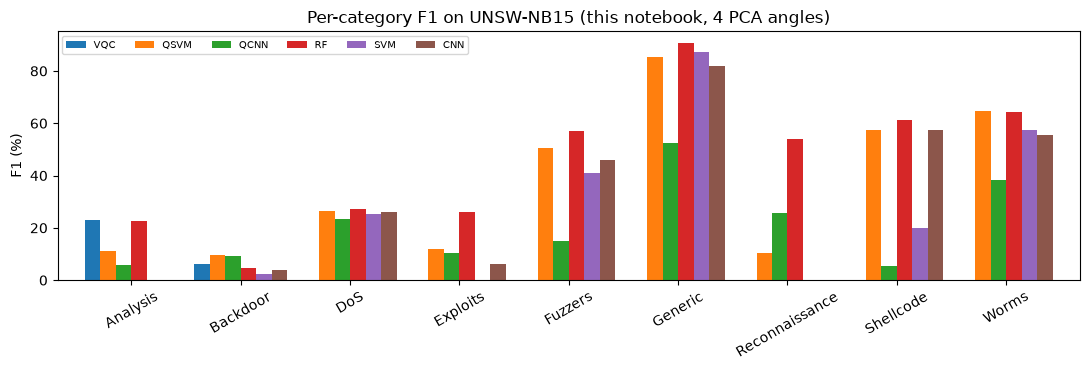

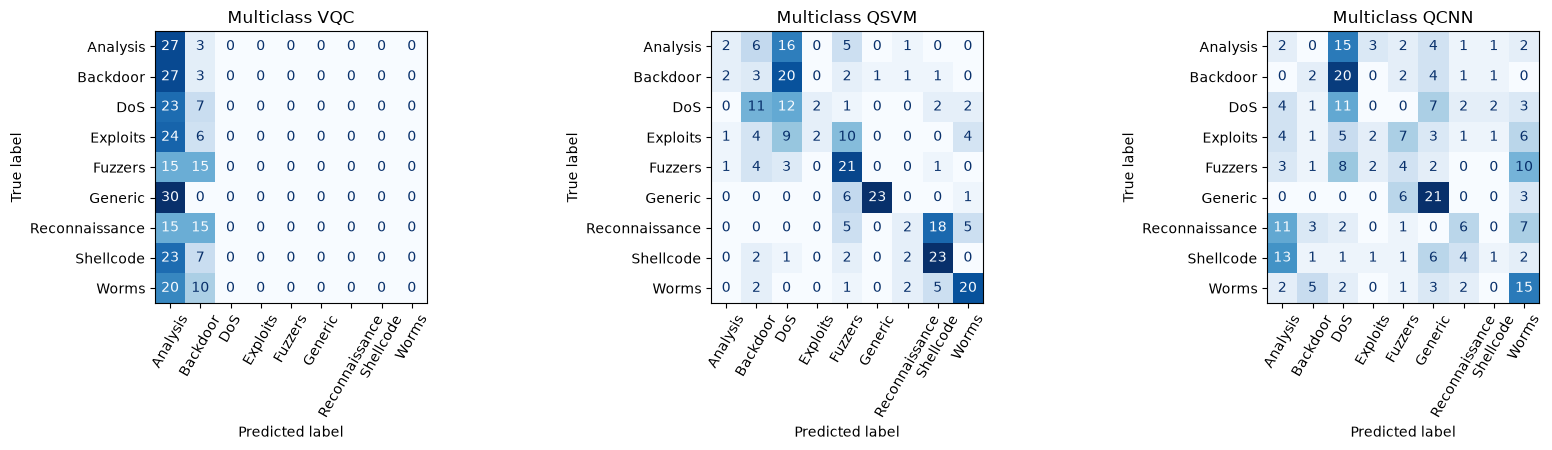

Verdicts on the macro-averaged F1 (within 2 points = reproduced; the paper's macro F1 is the unweighted mean of its 9 cells):
  VQC   paper macro F1  80.81 | notebook   3.26 -> not reached (-77.5)
  QSVM  paper macro F1  86.19 | notebook  36.36 -> not reached (-49.8)
  QCNN  paper macro F1  89.81 | notebook  20.63 -> not reached (-69.2)
  RF    paper macro F1  80.93 | notebook  45.29 -> not reached (-35.6)
  SVM   paper macro F1  79.83 | notebook  25.96 -> not reached (-53.9)
  CNN   paper macro F1  80.67 | notebook  30.79 -> not reached (-49.9)
categories (of 9) within 10 F1 points of the paper, per model: {'VQC': 0, 'QSVM': 2, 'QCNN': 0, 'RF': 1, 'SVM': 0, 'CNN': 1}
C6a 'Worms is the hardest category for every model': hardest category per model (this notebook): {'VQC': 'DoS', 'QSVM': 'Backdoor', 'QCNN': 'Shellcode', 'RF': 'Backdoor', 'SVM': 'Analysis', 'CNN': 'Analysis'} -> not reached here (VQC: DoS, QSVM: Backdoor, QCNN: Shellcode, RF: Backdoor, SVM: Analysis, CNN: Analysis)
C6b QM

In [34]:
if RUN_MULTICLASS:
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ours.drop(index="macro avg").plot.bar(ax=ax, width=.85, rot=30); ax.set_ylabel("F1 (%)"); ax.set_title("Per-category F1 on UNSW-NB15 (this notebook, 4 PCA angles)")
    ax.legend(fontsize=7, ncol=6); plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    for a_, name in zip(ax, [m for m in ["VQC", "QSVM", "QCNN"] if m in mc_pred]):
        ConfusionMatrixDisplay(confusion_matrix(ym_te, mc_pred[name], labels=range(len(ATTACKS))), display_labels=ATTACKS).plot(
            ax=a_, cmap="Blues", xticks_rotation=60, colorbar=False)
        a_.set_title(f"Multiclass {name}")
    plt.tight_layout(); plt.show()

    # Verdicts
    print("Verdicts on the macro-averaged F1 (within 2 points = reproduced; the paper's macro F1 is the unweighted mean of its 9 cells):")
    for m in paper_tab.columns:
        if m in ours.columns:
            o, p = ours.loc["macro avg", m], paper_tab.loc["macro avg", m]
            print(f"  {m:5s} paper macro F1 {p:6.2f} | notebook {o:6.2f} -> {verdict(o, p)}")
        else:
            print(f"  {m:5s} one-vs-rest multiclass QCNN skipped (RUN_QCNN_MULTICLASS = False in FAST_MODE) -> cannot be checked in this run")
    per_cell = {m: int((gap[m].abs() <= 10).sum()) for m in ours.columns if m in paper_tab.columns}
    print("categories (of 9) within 10 F1 points of the paper, per model:", per_cell)
    worst = {m: ours.drop(index="macro avg")[m].idxmin() for m in ours.columns}
    print("C6a 'Worms is the hardest category for every model': hardest category per model (this notebook):", worst,
          "->", "reproduced" if all(v == "Worms" for v in worst.values()) else "not reached here (" + ", ".join(f"{m}: {v}" for m, v in worst.items() if v != "Worms") + ")")
    q_mods = [m for m in ["VQC", "QSVM", "QCNN"] if m in ours.columns]
    lead = {c: bool(ours.loc[c, q_mods].min() > ours.loc[c, ["RF", "SVM", "CNN"]].max()) for c in ["Analysis", "Exploits", "Reconnaissance"]}
    lag = {c: bool(ours.loc[c, q_mods].max() < ours.loc[c, ["RF", "SVM", "CNN"]].max()) for c in ["Worms", "Shellcode"]}
    print("C6b QML leads (all quantum > all classical) on:", lead, "| paper: Exploits and Reconnaissance yes (Table V), Analysis only for VQC/QCNN vs RF")
    print("C6c best classical beats best quantum on Worms/Shellcode:", lag, "| paper: RF/SVM/CNN lead on Shellcode (80.12 vs 79.94), QCNN leads Worms (65.11)")

## 10b. How much does the small sample limit the models? A classical ceiling check

The quantum models are trained on a few hundred flows because a statevector simulator is slow. This cell asks how much of the gap to the paper is due to that sample size and not to the model: a random forest on all encoded features is trained on a much larger sample of the training partition (up to 40,000 flows for the binary task, up to 3,000 flows per attack category for the multiclass task) and evaluated on the **same test samples** as above. This is not part of the paper's protocol (`# CHOICE`); it is context for the numbers in the tables.

In [35]:
# classical ceiling: RF on all encoded features, much larger training sample, same test samples as above
big = train_part.sample(n=min(40000, len(train_part)), random_state=SEED)
enc_big = Pipeline([("enc", make_encoder()), ("std", StandardScaler())]).fit(big[FEATS])
rf_big = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(enc_big.transform(big[FEATS]), big["label"])
ceiling_bin = 100 * f1_score(y_test, rf_big.predict(enc_big.transform(te_df[FEATS])))
print(f"binary: RF on all features, {len(big):,} training flows -> test F1 = {ceiling_bin:.2f} % "
      f"(RF on {len(X_train)} flows: {f1(classic_full['RF']):.2f} %, paper RF: {PAPER_BINARY_UNSW['RF']:.2f} %)")

if RUN_MULTICLASS:
    bigm = pd.concat([train_part[train_part.attack_cat == a].sample(n=min(3000, (train_part.attack_cat == a).sum()), random_state=SEED) for a in ATTACKS])
    enc_m = Pipeline([("enc", make_encoder()), ("std", StandardScaler())]).fit(bigm[FEATS])
    rf_m = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2).fit(enc_m.transform(bigm[FEATS]), bigm["attack_cat"].map({a: i for i, a in enumerate(ATTACKS)}))
    ceil_mc = 100 * f1_score(ym_te, rf_m.predict(enc_m.transform(M["te"][FEATS])), average=None, labels=range(len(ATTACKS)), zero_division=0)
    ceil_df = pd.DataFrame({"RF, large sample, all features": ceil_mc, f"RF, {len(M['tr'])} flows, all features": ours_full["RF"].drop(index="macro avg").to_numpy(),
                            "paper RF (Table V)": PAPER_MC_UNSW["RF"].to_numpy()}, index=ATTACKS).round(2)
    ceil_df.loc["macro avg"] = ceil_df.mean().round(2)
    print(f"\nmulticlass: RF on {len(bigm):,} attack flows from the training partition, tested on the same {len(ym_te)} balanced test flows")
    display(ceil_df)

# facts used in 'Reading the paper critically'
print("\nfacts for the discussion")
print("  4-angle vs all-feature F1 gap per classical model (all features minus 4 angles, binary):",
      {k: round(f1(classic_full[k]) - f1(classic_q[k]), 1) for k in classic_q})
print(f"  spread of the repeated models over {len(SEEDS)} seeds (std of F1 points):", summary["std"].to_dict())
print(f"  VQC under device noise: simulator {ideal:.1f} %, per-device best {best_dev.round(1).to_dict()}; two-qubit gates after transpilation (opt 3): {noisy_df['2q gates (opt 3)'].iloc[0]}")

binary: RF on all features, 40,000 training flows -> test F1 = 88.49 % (RF on 300 flows: 87.53 %, paper RF: 82.67 %)



multiclass: RF on 20,009 attack flows from the training partition, tested on the same 270 balanced test flows


,"RF, large sample, all features","RF, 270 flows, all features",paper RF (Table V)
Analysis,15.00,37.93,90.23
Backdoor,16.13,9.30,92.11
DoS,18.18,27.03,82.56
Exploits,51.72,48.00,85.89
Fuzzers,65.82,71.88,79.78
Generic,98.31,92.06,99.01
Reconnaissance,93.55,86.21,82.89
Shellcode,83.08,73.97,80.12
Worms,77.55,70.18,35.78
macro avg,57.70,57.40,80.93



facts for the discussion
  4-angle vs all-feature F1 gap per classical model (all features minus 4 angles, binary): {'RF': 4.0, 'SVM': 2.0, 'CNN': 8.4}
  spread of the repeated models over 3 seeds (std of F1 points): {'QSVM': 1.93, 'RF': 0.96, 'SVM': 2.0, 'CNN': 3.29}
  VQC under device noise: simulator 76.8 %, per-device best {'ibm_cairo': 76.8, 'ibm_kyoto': 49.5, 'ibm_brisbane': 77.4, 'ibm_osaka': 76.8, 'ibm_sherbrooke': 76.8}; two-qubit gates after transpilation (opt 3): 6


## 11. Claim ledger

In [36]:
ledger = []
for m, p in PAPER_BINARY_UNSW.items():
    ledger.append(("C1", f"Table IV binary F1, {m}", p, round(ours4[m], 2), verdict(ours4[m], p)))
ledger.append(("C2", "all QML > all classical (binary)", "yes", "yes" if c2_all else "no", "reproduced" if c2_all else ("partly (best quantum above best classical)" if c2_best else "not reached here")))
ledger.append(("C3", "VQC is the best QML model (binary)", "yes", "yes" if c3 else "no", "reproduced" if c3 else "not reached here"))
for dev, p, o, v in c4_rows:
    ledger.append(("C4", f"VQC F1 on {dev}", p, round(o, 2), v))
ledger.append(("C4", "VQC within ~3 points of simulator on all devices", "yes", f"gap {gap_sim:.1f}", "reproduced" if gap_sim <= 3 else "not reached here"))
ledger.append(("C4", "QSVM / QCNN F1 on IBM devices (Tables II-III)", "see tables", "-", "cannot be checked"))
if RUN_MULTICLASS:
    for m in paper_tab.columns:
        if m in ours.columns:
            o, p = ours.loc["macro avg", m], paper_tab.loc["macro avg", m]
            ledger.append(("C5", f"Table V macro-F1, {m}", p, o, verdict(o, p)))
        else:
            ledger.append(("C5", f"Table V macro-F1, {m}", paper_tab.loc["macro avg", m], "-", "cannot be checked in this run"))
    ledger.append(("C6", "Worms hardest category for every model", "yes", "yes" if all(v == "Worms" for v in worst.values()) else "no",
                   "reproduced" if all(v == "Worms" for v in worst.values()) else "not reached here"))
    c6b = all(lead[c] for c in ["Exploits", "Reconnaissance"])
    ledger.append(("C6", "all QML > all classical on Exploits and Reconnaissance", "yes", "yes" if c6b else "no", "reproduced" if c6b else "not reached here"))
    ledger.append(("C6", "best classical > best quantum on Shellcode", "yes (80.12 vs 79.94)", "yes" if lag["Shellcode"] else "no", "reproduced" if lag["Shellcode"] else "not reached here"))
ledger_df = pd.DataFrame(ledger, columns=["claim", "what", "paper", "notebook", "verdict"])
display(ledger_df)
print(ledger_df["verdict"].str.split(" ").str[0].value_counts().to_dict())

,claim,what,paper,notebook,verdict
0,C1,"Table IV binary F1, VQC (tuned)",88.1,79.28,not reached (-8.8)
1,C1,"Table IV binary F1, QSVM",87.9,82.64,not reached (-5.3)
2,C1,"Table IV binary F1, QCNN",87.32,66.29,not reached (-21.0)
3,C1,"Table IV binary F1, RF",82.67,83.54,reproduced
4,C1,"Table IV binary F1, SVM",82.34,81.32,reproduced
5,C1,"Table IV binary F1, CNN",86.72,77.89,not reached (-8.8)
6,C2,all QML > all classical (binary),yes,no,not reached here
7,C3,VQC is the best QML model (binary),yes,no,not reached here
8,C4,VQC F1 on ibm_cairo,87.91,76.8,not reached (-11.1)
9,C4,VQC F1 on ibm_kyoto,88.1,49.54,not reached (-38.6)


{'not': 20, 'reproduced': 3, 'cannot': 1}


## Reading the paper critically

Some points to raise with students, whatever numbers your run produces:

- **The quantum models see 4 numbers per flow.** PCA compresses dozens of flow statistics into as many angles as there are qubits. Compare the classical baselines on the same 4 angles with the same baselines on all features: the gap measures what the qubit budget costs, independent of whether the model is quantum.
- **Simulation is not speed-up.** Every quantum result here was computed by a classical simulator. A 4-qubit circuit is easy to simulate, so these experiments cannot show a quantum advantage; they show that the hybrid pipeline works end to end.
- **Table IV is not one backend.** The three UNSW-NB15 QML values in Table IV (VQC 88.10, QSVM 87.90, QCNN 87.32) equal the entries of *different* devices in Tables II-III (VQC on IBM Kyoto, QSVM on IBM Cairo and Osaka, QCNN on IBM Brisbane), not the simulator column or one common device; the text says Table IV shows "the best results obtained in each model and backend combination". It is therefore a best-of-several comparison for the quantum side, set against classical baselines run once.
- **Quantum and classical are not like-for-like.** The paper does not say what input the RF, SVM and CNN received. The 4-angle versus all-feature gap of each classical model is printed in Section 10b; a "quantum beats classical" result depends on which classical input is chosen.
- **Noise.** The paper's device scores differ from the simulator by only 0-3 points, which is hard to square with ZZ-feature-map circuits of 100+ native gates on 2024 hardware unless the circuits were very shallow or heavily mitigated. The circuit that wins the validation search in the saved run is shallow (a Z feature map and `RealAmplitudes`, about 6 two-qubit gates after transpilation), and on four of the five stored device snapshots its F1 stays within 1 point of the noiseless simulator; on the fifth (IBM Kyoto) the layout the transpiler picks costs about 27 points. Small simulator-to-device gaps are therefore plausible for shallow circuits and say little about deeper ones; assign `noisy_model = vqc` (the default ZZ model) in the transpilation cell of the circuit section and rerun Section 9 to see the contrast.
- **Multiclass on four qubits.** Nine classes read from 16 outcomes of 4 qubits cannot be balanced (two classes own one outcome, seven own two). Table V's high VQC scores on several classes (Reconnaissance 98.88, Generic 97.01) are hard to obtain with the standard `outcome mod K` rule: in the saved run this read-out leaves the VQC close to chance on most categories. The paper does not say how classes were read out or how its test set was built.
- **Table V versus a classical ceiling.** Table V gives the random forest F1 above 90 on Analysis and Backdoor. Section 10b trains a random forest on thousands of flows and prints its per-category F1 on the same test flows: Analysis, Backdoor and DoS flows are commonly reported as hard to separate on the official partitions, and the ceiling check shows how far the classical rows of Table V are from what this pipeline reaches even with about 75 times more training data (in the saved run the ceiling macro F1 is no higher than the small-sample one, so the sample size is not what separates this notebook from Table V).
- **Duplicates.** Whether duplicate rows are removed changes the class mix of UNSW-NB15 drastically (almost all of "Generic" is duplicated). The paper does not say what it did, and reported F1 values are not comparable across papers without that information.
- **Test sets.** The class mix and size of the paper's test sets are unknown. The testing partition of UNSW-NB15 is known to be harder than random splits of the training partition (it contains different traffic), so the same model scores differently on a random split.
- **Sample size.** This notebook uses a few hundred flows per task, so expect run-to-run variation of a few points, especially for the small classes (Worms, Shellcode) in the multiclass task. The seed study (Section 8) puts numbers on this.

## Exercises

1. Set `RUN_FULL_GRID = True` and run Section 5b overnight. Does the coordinate-wise search find the same winner as the full grid, and does Table I's RawFeatureVector win?
2. Change `N_QUBITS` to 8 (the QCNN needs a power of two) and compare the 8-angle classical baselines with the quantum models. What does the extra PCA variance buy?
3. Replace the PCA by `SelectKBest(f_classif, k=N_QUBITS)` on the encoded features so that each qubit carries one named flow feature. Which four features does it pick, and does the VQC change?
4. Evaluate the binary models on a random split of the *training* partition instead of the official testing partition. How much easier is it, and what does that say about comparing numbers across papers?
5. Set `DROP_DUPLICATES = True` and rerun. How do the class mix of the test sample and the F1 of every model change?
6. Repeat the multiclass task with a one-hot read-out on 9 dedicated measurement outcomes (for example 4 qubits plus parity groups of your own design) instead of `outcome mod 9`. Does Worms stop being the worst class?

In [37]:
elapsed = (time.time() - NOTEBOOK_T0) / 60
print(f"FAST_MODE = {FAST_MODE}, RUN_FULL_GRID = {RUN_FULL_GRID}, RUN_MULTICLASS = {RUN_MULTICLASS}, RUN_QCNN_MULTICLASS = {RUN_QCNN_MULTICLASS}")
print(f"whole notebook: {elapsed:.1f} min wall clock | BEST = {BEST} | kernel map = {kernel_fm_name} (bandwidth {BW}, C {C_BEST})")

FAST_MODE = False, RUN_FULL_GRID = False, RUN_MULTICLASS = True, RUN_QCNN_MULTICLASS = True
whole notebook: 87.5 min wall clock | BEST = Combo(feature_map='ZFeatureMap', ansatz='RealAmplitudes', optimizer='COBYLA') | kernel map = ZFeatureMap (bandwidth 1.0, C 10.0)
